# Solar irradiance

## Dependencies

In [1]:
import sys, subprocess, importlib.util

deps = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn', 'xgboost': 'xgboost', 'lightgbm': 'lightgbm', 'catboost': 'catboost', 
        'optuna': 'optuna', 'tensorflow': 'tensorflow', 'shap': 'shap', 'matplotlib': 'matplotlib', 'nbformat': 'nbformat'}

missing = [pkg for mod, pkg in deps.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)

## Setup

In [2]:
from pathlib import Path
import os, sys, platform, json, hashlib, random, time, warnings

import numpy as np, pandas as pd, scipy, sklearn, optuna, matplotlib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError) as exc:
    warnings.warn(f'Deterministic TensorFlow ops are unavailable: {exc}', RuntimeWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
RUN_MODE = 'BALANCED'

N_OUTER = 5
N_INNER = 3
TPE_OUTER = 10 if RUN_MODE == 'BALANCED' else 18
TPE_FINAL = 20 if RUN_MODE == 'BALANCED' else 36
MLP_TRIALS_OUTER = 6 if RUN_MODE == 'BALANCED' else 10
MLP_TRIALS_Final = 10 if RUN_MODE == 'BALANCED' else 16
CI_BOOTSTRAP_REFITS = 100

In [3]:
RUN_SUPPLEMENTARY_HORIZONS = False
RUN_SHAP = True
SHAPTREE_SAMPLE_Size = 1200
SHAPFALLBACK_SAMPLE_Size = 120
SHAPBACKGROUND_Size = 60
HORIZON_Min = 120
S2_FOLD_SCREEN_Confidence = 0.95
DayBlock_Reps = 3000
ENABLE_ExPlor_TestTieBreak = True


IS_Kaggle = Path('/kaggle/working').is_dir()
BASE = Path('/kaggle/working') if IS_Kaggle else Path.cwd()
DataSearch = [BASE / 'SolarPrediction.csv', Path.cwd() / 'SolarPrediction.csv']
if Path('/kaggle/input').exists():
    DataSearch.extend(sorted(Path('/kaggle/input').rglob('SolarPrediction.csv')))

CSV = next((p for p in DataSearch if p.is_file()), None)


OUT = BASE / 'Results'
OUT.mkdir(parents=True, exist_ok=True)

RawHash = hashlib.sha256(CSV.read_bytes()).hexdigest()
cache_key = (RawHash, SEED, HORIZON_Min, RUN_MODE, N_OUTER, N_INNER, TPE_OUTER, TPE_FINAL,
    MLP_TRIALS_OUTER, MLP_TRIALS_Final, np.__version__, sklearn.__version__, optuna.__version__,
    tf.__version__)

## Data

In [4]:
src = pd.read_csv(CSV)


src = src.sort_values('UNIXTime', kind='stable').reset_index(drop=True)


src['local_time'] = pd.to_datetime(src.UNIXTime, unit='s',
    utc = True).dt.tz_convert('Pacific/Honolulu')

src['time_of_day'] = src.local_time.dt.hour * 60 + src.local_time.dt.minute + src.local_time.dt.second / 60
src['month'] = src.local_time.dt.month
src['daylength'] = (pd.to_timedelta(src.TimeSunSet) - pd.to_timedelta(src.TimeSunRise)).dt.total_seconds() / 60
Featues = ['time_of_day', 'Temperature', 'Humidity', 'daylength', 'WindDirection(Degrees)',
    'month', 'Pressure', 'Speed']


GapThresholdSec = 600
TargetToleranceSec = 150
secs = np.diff(src.UNIXTime)
src['segment'] = np.r_[0, np.cumsum(secs > GapThresholdSec)]
src['rowid'] = np.arange(len(src), dtype=int)
split_raw = int(len(src) * 0.8)
left = src[['rowid', 'UNIXTime', 'segment', 'Radiation']].copy()
left['desired_target_unix'] = left.UNIXTime + HORIZON_Min * 60
right = src[['rowid', 'UNIXTime', 'segment', 'Radiation', 'TimeSunRise',
    'TimeSunSet']].rename(columns={'rowid': 'target_row', 'UNIXTime': 'actual_target_unix',
    'segment': 'target_segment', 'Radiation': 'y_target', 'TimeSunRise': 'target_sunrise',
    'TimeSunSet': 'target_sunset'})

matched = pd.merge_asof(left.sort_values('desired_target_unix'),
    right.sort_values('actual_target_unix'), left_on='desired_target_unix',
    right_on='actual_target_unix', direction='nearest',
    tolerance=TargetToleranceSec).sort_values('rowid')

matched_keep = matched.target_row.notna() & (matched.segment == matched.target_segment) & ~((matched.rowid < split_raw) & (matched.target_row >= split_raw))
matched_all = matched.loc[matched_keep].copy()
target_clock_local = pd.to_datetime(matched_all.actual_target_unix.to_numpy(), unit='s',
    utc=True).tz_convert('Pacific/Honolulu')

target_clock_seconds = target_clock_local.hour * 3600 + target_clock_local.minute * 60 + target_clock_local.second
sunrise_seconds = pd.to_timedelta(matched_all.target_sunrise).dt.total_seconds().to_numpy()
sunset_seconds = pd.to_timedelta(matched_all.target_sunset).dt.total_seconds().to_numpy()
daylight_keep = (target_clock_seconds > sunrise_seconds) & (target_clock_seconds < sunset_seconds)
rows = matched_all.loc[daylight_keep].sort_values('rowid', kind='stable').reset_index(drop=True)

In [5]:
ids = rows.rowid.astype(int).to_numpy()
is_train = ids < split_raw
is_test = ~is_train
X = src.loc[ids, Featues].to_numpy(dtype='float64')
y = rows.y_target.to_numpy(dtype='float64')
orig_irr = rows.Radiation.to_numpy(dtype='float64')
issue_time = src.loc[ids, 'local_time'].reset_index(drop=True)
target_time = pd.to_datetime(rows.actual_target_unix.to_numpy(), unit='s',
    utc = True).tz_convert('Pacific/Honolulu')

target_clock_bins = np.asarray(target_time.hour * 2 + target_time.minute // 30, dtype=int)
issue_local_clock = (issue_time.dt.hour * 3600 + issue_time.dt.minute * 60 + issue_time.dt.second).to_numpy()
issue_sunrise_sec = pd.to_timedelta(src.loc[ids, 'TimeSunRise']).dt.total_seconds().to_numpy()
issued_before_sunrise = issue_local_clock < issue_sunrise_sec




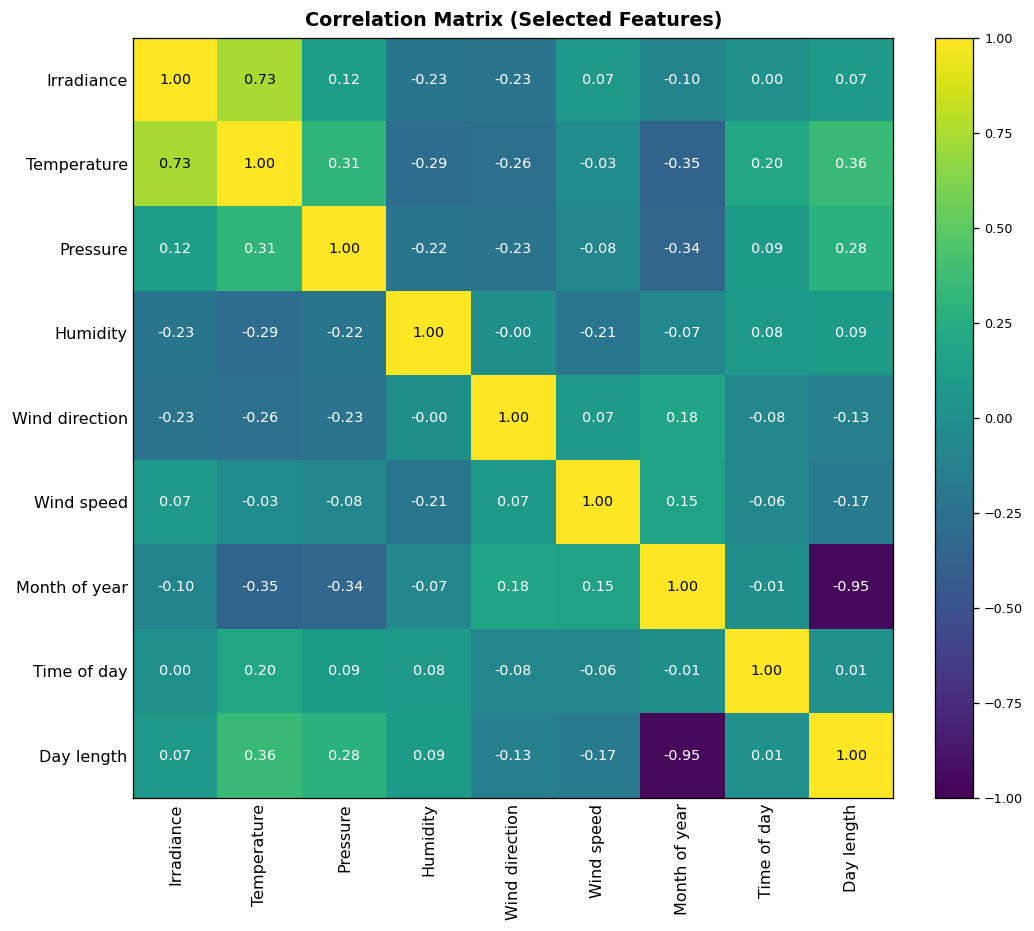

In [6]:
Plot_FeaturesNames = {'time_of_day': 'Time of Day', 'Temperature': 'Temperature', 'Humidity': 'Humidity', 'daylength': 'Day Length',
                    'WindDirection(Degrees)': 'Wind Direction','month': 'Month of Year', 'Pressure': 'Pressure', 'Speed': 'Wind Speed'}

_correlation_columns = ['Radiation', 'Temperature', 'Pressure', 'Humidity', 'WindDirection(Degrees)', 'Speed', 'month', 'time_of_day', 'daylength']

_original_labels = ['Irradiance', 'Temperature', 'Pressure', 'Humidity', 'Wind direction', 'Wind speed', 'Month of year', 'Time of day', 'Day length']

_corr_data = src.loc[:, _correlation_columns].apply(pd.to_numeric, errors='raise')
cor = _corr_data.corr(method='pearson').to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(10, 8.2))
im = ax.imshow(cor, cmap='viridis', vmin=-1, vmax=1, aspect='equal', interpolation='nearest')
ax.set_xticks(np.arange(9), labels=_original_labels, rotation=90)
ax.set_yticks(np.arange(9), labels=_original_labels)
ax.tick_params(axis='both', which='both', length=0, labelsize=10)
ax.set_title('Correlation Matrix (Selected Features)', fontweight='bold', fontsize=12, pad=7)
for _i in range(9):
    for _j in range(9):
        _v = float(cor[_i, _j])
        ax.text(_j, _i, f'{_v:.2f}', ha='center', va='center', fontsize=9,
            color = 'black' if _v > 0.48 else 'white')


bar = fig.colorbar(im, ax=ax, fraction=0.044, pad=0.04)
bar.ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(OUT / 'Correlation.png', dpi=240, bbox_inches='tight')
fig.set_dpi(115)

plt.show()
plt.close(fig)

## Models

In [7]:
Models = ['Random Forest', 'Extra Trees', 'KNN', 'XGBoost', 'LightGBM', 'CatBoost', 'MLP']

def quality(y_true, y_pred):
    return {'MAE': float(mean_absolute_error(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))), 'R2': float(r2_score(y_true,
        y_pred))}

def search_parameters(model, trial):
    if model in ['Random Forest', 'Extra Trees']:
        p = {'n_estimators': trial.suggest_categorical('n_estimators', [100, 200, 300, 400]),
            'max_depth': trial.suggest_categorical('max_depth', [4, 6, 8, 10, 12, 16, 20, None]),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 64, log=True),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 32),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5, 1.0])}
        if model == 'Random Forest':
            p.update(bootstrap=True, max_samples=trial.suggest_categorical('max_samples', [0.6, 0.8,
                1.0]))
        else:
            p['bootstrap'] = trial.suggest_categorical('bootstrap', [False, True])
        return p
    if model == 'KNN':
        return {'n_neighbors': trial.suggest_int('n_neighbors', 3, 128, log=True),
            'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
            'p': trial.suggest_categorical('p', [1, 2])}
    if model == 'XGBoost':
        return {'n_estimators': trial.suggest_categorical('n_estimators', [100, 200, 400, 600]),
            'max_depth': trial.suggest_int('max_depth', 2, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.15, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 32.0, log=True),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 10.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 100.0, log=True)}
    if model == 'LightGBM':
        depth = trial.suggest_int('max_depth', 3, 10)
        return {'n_estimators': trial.suggest_categorical('n_estimators', [100, 200, 400, 600]),
            'max_depth': depth, 'num_leaves': trial.suggest_int('num_leaves', 7, min(127,
            2 ** depth)), 'max_bin': trial.suggest_categorical('max_bin', [63, 127, 255]),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 150),
            'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 10.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 100.0, log=True)}
    if model == 'CatBoost':
        return {'iterations': trial.suggest_categorical('iterations', [40, 80, 160, 320, 500]),
            'depth': trial.suggest_int('depth', 3, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 0.1, 100.0, log=True),
            'random_strength': trial.suggest_float('random_strength', 0.0, 3.0),
            'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 2.0)}
    if model == 'MLP':
        return {'learning_rate': trial.suggest_float('learning_rate', 0.0001, 0.01, log=True),
            'batch_size': trial.suggest_categorical('batch_size', [32, 64, 128, 256]),
            'dropout_1': trial.suggest_float('dropout_1', 0.0, 0.4),
            'dropout_2': trial.suggest_float('dropout_2', 0.0, 0.4), 'l2': trial.suggest_float('l2',
            1e-07, 0.01, log=True), 'epochs': trial.suggest_categorical('epochs', [20, 32, 48])}
    raise KeyError(model)

def make_estimator(model, p):
    if model == 'Random Forest':
        return RandomForestRegressor(**p, random_state=SEED)
    if model == 'Extra Trees':
        return ExtraTreesRegressor(**p, random_state=SEED)
    if model == 'KNN':
        return Pipeline([('train_scaler', StandardScaler()), ('knn', KNeighborsRegressor(**p,
            metric = 'minkowski'))])
    if model == 'XGBoost':
        return XGBRegressor(**p, objective='reg:squarederror', tree_method='hist', random_state = SEED)
    if model == 'LightGBM':
        return LGBMRegressor(**p, subsample_freq=1, deterministic=True, force_col_wise=True,
            verbosity=-1, random_state=SEED)
    if model == 'CatBoost':
        return CatBoostRegressor(**p, bootstrap_type='Bayesian', loss_function='RMSE',
            verbose=False, random_seed=SEED)
    raise ValueError('MLP separately trained in Keras')

def _lightgbm_features(x):
    a = np.asarray(x, dtype=np.float64)
    return pd.DataFrame(a, columns=Featues)

def _keras_predict_eager(net, x_scaled):
    tensor = tf.convert_to_tensor(np.asarray(x_scaled, dtype=np.float32))
    return np.asarray(net(tensor, training=False).numpy(), dtype=float)

def physical_projection(raw):
    return np.maximum(0.0, np.asarray(raw, dtype=float).reshape(-1))

def predict_fitted_model_raw(model, artifact, x):
    if model == 'MLP':
        net, x_scaler, y_scaler = artifact
        z = x_scaler.transform(np.asarray(x, dtype=float)).astype('float32')
        return y_scaler.inverse_transform(_keras_predict_eager(net, z)).reshape(-1)
    if model == 'LightGBM':
        return np.asarray(artifact.predict(_lightgbm_features(x)), dtype=float).reshape(-1)
    return np.asarray(artifact.predict(np.asarray(x, dtype=float)), dtype=float).reshape(-1)

def predict_fitted_model(model, artifact, x):
    return physical_projection(predict_fitted_model_raw(model, artifact, x))

In [8]:
def fit_model_and_predict(model, p, x_fit, y_fit, x_eval, return_artifact=False):
    if model != 'MLP':
        est = make_estimator(model, p)
        fit_features = _lightgbm_features(x_fit) if model == 'LightGBM' else x_fit
        est.fit(fit_features, y_fit)
        y_pred = predict_fitted_model(model, est, x_eval)
        return (y_pred, est) if return_artifact else y_pred
    xs = StandardScaler().fit(x_fit)
    ys = StandardScaler().fit(np.asarray(y_fit).reshape(-1, 1))
    a = xs.transform(x_fit).astype('float32')
    b = xs.transform(x_eval).astype('float32')
    target = ys.transform(np.asarray(y_fit).reshape(-1, 1)).astype('float32')
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    regular = tf.keras.regularizers.l2(float(p['l2']))
    net = tf.keras.Sequential([tf.keras.layers.Input(shape=(8,)), tf.keras.layers.Dense(98,
        activation = 'relu', kernel_regularizer=regular),
        tf.keras.layers.Dropout(float(p['dropout_1']), seed=SEED), tf.keras.layers.Dense(37,
        activation='relu', kernel_regularizer=regular),
        tf.keras.layers.Dropout(float(p['dropout_2']), seed=SEED + 1), tf.keras.layers.Dense(1)])
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(p['learning_rate'])),
        loss='mse')
    net.fit(a, target, epochs=int(p['epochs']), batch_size=int(p['batch_size']), shuffle=False,
        verbose=0)
    pred = physical_projection(ys.inverse_transform(_keras_predict_eager(net, b)).reshape(-1))
    return (pred, (net, xs, ys)) if return_artifact else pred


def model_complexity_index(model, p):
    if model in ('Random Forest', 'Extra Trees'):
        depth = p.get('max_depth') or 32
        return float(p['n_estimators'] * depth / max(p['min_samples_leaf'], 1))
    if model == 'KNN':
        return float((1.5 if p['weights'] == 'distance' else 1.0) / p['n_neighbors'])
    if model == 'XGBoost':
        return float(p['n_estimators'] * 2 ** p['max_depth'] * p['learning_rate'] / (max(1,
            p['min_child_weight']) * (1 + p['reg_lambda'] + p['reg_alpha'])))
    if model == 'LightGBM':
        return float(p['n_estimators'] * p['num_leaves'] * p['learning_rate'] / (max(1,
            p['min_child_samples']) * (1 + p['reg_lambda'] + p['reg_alpha'])))
    if model == 'CatBoost':
        return float(p['iterations'] * 2 ** p['depth'] * p['learning_rate'] / (1 + p.get('l2_leaf_reg',
            0)))
    if model == 'MLP':
        widths = (p.get('hidden1', 98), p.get('hidden2', 37))
        return float((8 * widths[0] + widths[0] * widths[1] + widths[1]) * p.get('epochs',
            24) / (1 + 10 * (p.get('dropout_1', 0) + p.get('dropout_2', 0)) / 2 + p.get('l2',
            0) * 1000))
    raise ValueError(model)

## Helpers

In [9]:
from scipy.stats import t as _s2_t_dist


def _paired_s2_screen(fold_scores, model_a, model_b, confidence=S2_FOLD_SCREEN_Confidence):
    left = fold_scores.loc[fold_scores.Model == model_a, ['Fold',
        'S2_Topsis_2C_10Weights']].set_index('Fold')
    right = fold_scores.loc[fold_scores.Model == model_b, ['Fold',
        'S2_Topsis_2C_10Weights']].set_index('Fold')
    diff = (left.S2_Topsis_2C_10Weights - right.S2_Topsis_2C_10Weights).to_numpy(float)
    dmean = float(diff.mean())
    dsd = float(diff.std(ddof=1))
    dse = dsd / np.sqrt(len(diff))
    half = float(_s2_t_dist.ppf((1 + confidence) / 2, len(diff) - 1) * dse)
    lower = dmean - half
    upper = dmean + half
    close = bool(lower <= 1e-12 and upper >= -1e-12)
    return {'Model': model_b, 'Paired_Mean_Score_Gap': dmean, 'Paired_Fold_SD': dsd,
        'Paired_Fold_SE': dse, 'Score_Gap_Descriptive_95CI_Low': lower,
        'Score_Gap_Descriptive_95CI_High': upper, 'NearFirst_FoldUncertainty': close}

## Cross-validation

In [10]:
raw_ids = ids[is_train]
row_targets = rows.loc[is_train, 'target_row'].astype(int).to_numpy()
X_train_all = X[is_train]
y_train_all = y[is_train]
TRAIN_MASK = np.flatnonzero(is_train)


def purged_splits(base_indices, n_splits):
    for tr_loc, v_loc in TimeSeriesSplit(n_splits=n_splits).split(base_indices):
        tr = base_indices[tr_loc]
        val = base_indices[v_loc]
        first_issue = int(raw_ids[val[0]])
        tr = tr[row_targets[tr] < first_issue]

        yield (tr, val)


TPETrialRecords = []
oneSE_selectionrecords = []

In [11]:
def tune_model(model, outer_train_indices, budget, tag):
    inner = list(purged_splits(np.asarray(outer_train_indices, dtype=int), N_INNER))
    seed = SEED + sum((ord(c) for c in model + str(tag)))
    sampler = optuna.samplers.TPESampler(seed=seed, n_startup_trials=min(3, budget))
    study = optuna.create_study(direction='minimize', sampler=sampler)
    def objective(trial):
        p = search_parameters(model, trial)
        sse = 0.0
        abs_err = 0.0
        n = 0
        val_fold_rmses = []
        tr_fold_rmses = []

        fold_ratios = []
        train_r2s = []
        val_r2s = []
        signed_r2_gaps = []
        abs_r2_gaps = []
        pers_squared_error = 0.0
        for inn, (it, iv) in enumerate(inner):
            pred_tr, est = fit_model_and_predict(model, p, X_train_all[it], y_train_all[it],
                X_train_all[it], return_artifact=True)
            pred_val = predict_fitted_model(model, est, X_train_all[iv])
            yv = y_train_all[iv]
            tr_rmse=quality(y_train_all[it], pred_tr)['RMSE']
            val_rmse = quality(yv, pred_val)['RMSE']

            tr_fold_rmses.append(tr_rmse)
            val_fold_rmses.append(val_rmse)
            train_r2 = float(r2_score(y_train_all[it], pred_tr))
            val_r2 = float(r2_score(yv, pred_val))
            signed_gap = train_r2 - val_r2
            train_r2s.append(train_r2)
            val_r2s.append(val_r2)
            signed_r2_gaps.append(signed_gap)
            abs_r2_gaps.append(abs(signed_gap))
            fold_ratios.append(val_rmse / max(tr_rmse, 1e-08))
            sse += float(np.sum((pred_val - yv) ** 2))
            abs_err += float(np.sum(np.abs(pred_val - yv)))
            n += len(iv)
            persistence_val = orig_irr[is_train][iv]
            pers_squared_error += float(np.sum((persistence_val - yv) ** 2))
        rmse = float(np.sqrt(sse / n))
        mae = float(abs_err / n)
        gap_ratio= float(np.mean([max(v - t, 0) / max(v, 1e-08) for v, t in zip(val_fold_rmses,
            tr_fold_rmses)]))
        trial.set_user_attr('inner_mae', mae)
        trial.set_user_attr('inner_persistence_rmse', float(np.sqrt(pers_squared_error / n)))
        trial.set_user_attr('complexity_index', model_complexity_index(model, p))
        trial.set_user_attr('fold_validation_RMSE', val_fold_rmses)
        trial.set_user_attr('fold_train_RMSE', tr_fold_rmses)
        trial.set_user_attr('mean_relative_generalization_gap', gap_ratio)
        trial.set_user_attr('max_val_train_ratio', float(np.max(fold_ratios)))
        trial.set_user_attr('inner_train_r2_by_fold', train_r2s)
        trial.set_user_attr('inner_val_r2_by_fold', val_r2s)
        trial.set_user_attr('inner_r2_gap_signed_by_fold', signed_r2_gaps)
        trial.set_user_attr('inner_r2_gap_absolute_by_fold', abs_r2_gaps)
        trial.set_user_attr('inner_r2_gap_abs_mean', float(np.mean(abs_r2_gaps)))
        trial.set_user_attr('inner_val_r2_mean', float(np.mean(val_r2s)))
        TPETrialRecords.append({'Stage': str(tag),
                'Model': model, 'Trial': trial.number,
            'Inner_Validation_RMSE': rmse, 'Inner_Validation_MAE': mae,
            'Inner_Train_RMSE_Mean': float(np.mean(tr_fold_rmses)),
            'Inner_Validation_RMSE_SD': float(np.std(val_fold_rmses, ddof=1)),
            'Generalization_Gap_Positive_Relative': gap_ratio,
            'Inner_Persistence_RMSE': float(np.sqrt(pers_squared_error / n)),
            'Complexity_Index': model_complexity_index(model, p),
            'Worst_Val_Train_RMSE_Ratio': float(np.max(fold_ratios)), 'Inner_Train_R2_Mean': float(np.mean(train_r2s)),
            'Inner_Validation_R2_Mean': float(np.mean(val_r2s)),
            'R2_Gap_Train_minus_Validation_Mean': float(np.mean(signed_r2_gaps)),
            'R2_Gap_Absolute_Mean': float(np.mean(abs_r2_gaps)),
            'R2_Gap_Absolute_Max': float(np.max(abs_r2_gaps)),
            'R2_Gap_Absolute_by_Inner_Fold': json.dumps(abs_r2_gaps),
                    'Parameters': json.dumps(p,
            sort_keys=True)})
        return rmse
    study.optimize(objective, n_trials=budget, gc_after_trial=model == 'MLP',
        show_progress_bar=False)
    valid = [t for t in study.trials if t.value is not None and np.isfinite(t.value)]
    best = min(valid, key=lambda t: (t.value,
            t.user_attrs.get('inner_mae', float('inf')),
        t.number))
    folds= np.asarray(best.user_attrs['fold_validation_RMSE'], dtype=float)
    one_se = float(np.std(folds, ddof=1) / np.sqrt(len(folds)))
    eligible = [t for t in valid if float(t.value) <= float(best.value) + one_se + 1e-12]
    skillful = [t for t in eligible if float(t.value) < float(t.user_attrs['inner_persistence_rmse'])]
    chosen = best
    pool = eligible
    selection_note = 'MIN_INNER_CV_RMSE;ONE_SE_AND_GENERALIZATION_DIAGNOSTIC_ONLY'
    by_gap= sorted(pool, key=lambda t: (float(t.user_attrs['mean_relative_generalization_gap']),
        t.number))
    by_complexity = sorted(pool, key=lambda t: (float(t.user_attrs['complexity_index']), t.number))
    gap_rank = {t.number: i + 1 for i, t in enumerate(by_gap)}

    complexity_rank = {t.number: i + 1 for i, t in enumerate(by_complexity)}
    oneSE_selectionrecords.append({'Stage': str(tag), 'Model': model,
                'Trials': len(valid), 'Selected_Gap_Rank': gap_rank[chosen.number],
        'Selected_Complexity_Rank': complexity_rank[chosen.number],
        'Selected_Balanced_Rank_Sum': None, 'All_Selection_Candidates': len(pool),
        'Best_RMSE_Trial': best.number, 'Best_Inner_RMSE': float(best.value),
        'One_SE_Descriptive_Tolerance': one_se, 'Candidate_Count_Within_1SE': len(eligible),
        'Candidates_Also_Beating_Persistence': len(skillful), 'Selected_Trial': chosen.number,
        'Selected_Inner_RMSE': float(chosen.value),
        'Selected_Inner_Persistence_RMSE': float(chosen.user_attrs['inner_persistence_rmse']),
        'Selected_Complexity_Index': float(chosen.user_attrs['complexity_index']),
        'Selected_Relative_Generalization_Gap': chosen.user_attrs['mean_relative_generalization_gap'],
        'Selected_Max_Inner_Val_Train_RMSE_Ratio': chosen.user_attrs['max_val_train_ratio'],
        'Selected_Inner_Mean_Abs_R2_Gap_DIAGNOSTIC': chosen.user_attrs['inner_r2_gap_abs_mean'],
        'Selection_Status': selection_note,
        'Decision': 'Minimum pooled inner held-out RMSE; MAE as exact-tie breaker. One-SE band, complexity, Train/CV gaps and persistence are descriptive ONLY. No Test-tuned selection.',
        'Chosen_Parameters': json.dumps(chosen.params, sort_keys=True)})
    return (chosen.params, float(chosen.value))

In [12]:
import pickle


def _atomic_pickle(value, path):
    temporary = Path(str(path) + '.partial')
    with open(temporary, 'wb') as f:
        pickle.dump(value, f, protocol=pickle.HIGHEST_PROTOCOL)
        f.flush()
        os.fsync(f.fileno())
    temporary.replace(path)


cache_dir = OUT / 'cache_v25'
cache_dir.mkdir(exist_ok=True)
cv_cache = cache_dir / 'Outer_Models.pkl'
if cv_cache.exists():
    with open(cv_cache, 'rb') as f:
        saved = pickle.load(f)
    if saved.get('cache_key') != cache_key:
        raise RuntimeError('Cached CV settings differ from the current data or parameters.')
    foldrecords = saved['fold_records']
    OOFrecords = saved['oof_records']
    hyperfold = saved['hyper_folds']
    TPETrialRecords = saved['tpe_trial_records']
    oneSE_selectionrecords = saved['one_se_selection_records']
else:
    foldrecords = []
    OOFrecords = []
    hyperfold = []

Completed_pairs= {(r['Fold'], r['Model']) for r in hyperfold}
base_indices = np.arange(len(X_train_all))
for fold, (outer_tr, outer_val) in enumerate(purged_splits(base_indices, N_OUTER), start=1):
    tvals = pd.to_datetime(rows.loc[TRAIN_MASK[outer_val], 'actual_target_unix'].to_numpy(),
        unit='s', utc=True).tz_convert('Pacific/Honolulu').astype(str)
    for model in Models:
        if (fold, model) in Completed_pairs:
            continue
        trial_count = MLP_TRIALS_OUTER if model == 'MLP' else TPE_OUTER
        pars, score = tune_model(model, outer_tr, trial_count, 'outer_' + str(fold))
        pred_train, artifact = fit_model_and_predict(model, pars, X_train_all[outer_tr],
            y_train_all[outer_tr], X_train_all[outer_tr], return_artifact=True)
        pred = predict_fitted_model(model, artifact, X_train_all[outer_val])
        raw_oof_pred= predict_fitted_model_raw(model, artifact,
                X_train_all[outer_val])
        q = quality(y_train_all[outer_val], pred)
        qtrain = quality(y_train_all[outer_tr], pred_train)
        ratio = float(q['RMSE'] / max(qtrain['RMSE'], 1e-08))
        r2drop = float(qtrain['R2'] - q['R2'])

        abs_r2drop= abs(r2drop)

        foldrecords.append({'Fold': fold, 'Model': model, 'Train_N': len(outer_tr),
            'Validation_N': len(outer_val), **q,
            'Raw_Negative_Validation_Predictions': int(np.sum(raw_oof_pred < 0)),
            'Nonnegative_Prediction_Projection': True,
                    'Train_RMSE': qtrain['RMSE'], 'Train_R2': qtrain['R2'], 'Val_to_Train_RMSE_Ratio': ratio,
            'Train_minus_Val_R2': r2drop, 'Abs_R2_Train_Val_Gap': abs_r2drop,
            'Validation_to_Train_RMSE_Relative_Excess': float((q['RMSE'] - qtrain['RMSE']) / max(qtrain['RMSE'],
            1e-08))})
        hyperfold.append({'Fold': fold, 'Model': model, 'Inner_RMSE': score,
            'Parameters': json.dumps(pars, sort_keys=True)})
        OOFrecords.extend(({'Fold': fold, 'Model': model, 'Issue_Row': int(raw_ids[k]),
            'Actual': float(y_train_all[k]), 'Predicted': float(pred[j]),
            'Target_Local': str(tvals[j])} for j, k in enumerate(outer_val)))
        _atomic_pickle({'cache_key': cache_key, 'fold_records': foldrecords,
            'oof_records': OOFrecords, 'hyper_folds': hyperfold, 'tpe_trial_records': TPETrialRecords,
            'one_se_selection_records': oneSE_selectionrecords}, cv_cache)

fold_df = pd.DataFrame(foldrecords)
oof_df = pd.DataFrame(OOFrecords)


pooled_df = pd.DataFrame([{'Model': m, 'N': len(g), **quality(g.Actual.to_numpy(),
    g.Predicted.to_numpy())} for m, g in oof_df.groupby('Model')])

2026-10-29 00:25:49.650493: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-10-29 00:25:49.998372: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-29 00:25:55.192318: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_un

In [13]:
display(pooled_df.round(3))

,Model,N,MAE,RMSE,R2
0,CatBoost,9680,150.029,210.123,0.603
1,Extra Trees,9680,151.596,210.924,0.600
2,KNN,9680,181.252,225.114,0.545
3,LightGBM,9680,148.658,207.810,0.612
4,MLP,9680,188.935,243.714,0.466
5,Random Forest,9680,144.143,202.572,0.631
6,XGBoost,9680,153.680,217.063,0.577


## Baseline

In [14]:
def calculate_topsis(frame):
    matrix = frame[['RMSE', 'MAE']].to_numpy(dtype=float)
    normal = matrix / np.sqrt((matrix ** 2).sum(axis=0))
    output = frame[['Model']].reset_index(drop=True).copy()
    for s in range(1, 11):
        w = np.array([s / 10, 1 - s / 10], dtype=float)
        v = normal * w
        ideal = v.min(axis=0)
        anti = v.max(axis=0)
        d_good = np.sqrt(((v - ideal) ** 2).sum(axis=1))
        d_bad = np.sqrt(((v - anti) ** 2).sum(axis=1))
        output[f'S{s}'] = np.divide(d_bad, d_good + d_bad, out=np.full(len(d_good), 0.5),
            where = d_good + d_bad > 0)
    output['Mean_TOPSIS'] = output[[f'S{s}' for s in range(1, 11)]].mean(axis=1)
    return output.sort_values(['Mean_TOPSIS', 'Model'], ascending=[False, True]).reset_index(drop=True)


topsis = calculate_topsis(pooled_df)
SingleMetricSensitivity = pooled_df[['Model', 'MAE', 'RMSE']].copy()
SingleMetricSensitivity['Rank_Pure_MAE'] = SingleMetricSensitivity.MAE.rank(method='min').astype(int)
SingleMetricSensitivity['Rank_Pure_RMSE'] = SingleMetricSensitivity.RMSE.rank(method='min').astype(int)


def pure_one_cost_topsis(vals):
    vals = np.asarray(vals, dtype=float)
    maxv, minv = (vals.max(), vals.min())
    if np.isclose(maxv, minv):
        return np.full(len(vals), 0.5)
    return (maxv - vals) / (maxv - minv)


SingleMetricSensitivity['Pure_MAE_TOPSIS_Score'] = pure_one_cost_topsis(SingleMetricSensitivity.MAE)
SingleMetricSensitivity['Pure_RMSE_TOPSIS_Score'] = pure_one_cost_topsis(SingleMetricSensitivity.RMSE)
CV_Generalization = fold_df.groupby('Model').agg(Outer_Mean_Signed_R2_Train_minus_Validation=('Train_minus_Val_R2',
    'mean'), Outer_Mean_Abs_R2_Gap=('Abs_R2_Train_Val_Gap', 'mean'),
    Outer_SD_Abs_R2_Gap=('Abs_R2_Train_Val_Gap', 'std'),
    Outer_Max_Abs_R2_Gap=('Abs_R2_Train_Val_Gap', 'max'),
    Outer_Mean_Val_to_Train_RMSE_Ratio=('Val_to_Train_RMSE_Ratio', 'mean'),
    Outer_Validation_R2_Mean=('R2', 'mean'), Outer_Validation_RMSE_Mean=('RMSE', 'mean')).reset_index()

outerskill_rows = []
for (m, fold), g in oof_df.groupby(['Model', 'Fold'], sort=True):
    issue_rows = g['Issue_Row'].to_numpy(dtype=int)
    observed = g['Actual'].to_numpy(dtype=float)
    persistence = src.loc[issue_rows, 'Radiation'].to_numpy(dtype=float)
    pred = g['Predicted'].to_numpy(dtype=float)
    p_rmse = float(np.sqrt(np.mean((observed - persistence) ** 2)))
    v_rmse = float(np.sqrt(np.mean((observed - pred) ** 2)))
    outerskill_rows.append({'Model': m, 'Outer_Fold': int(fold), 'Validation_RMSE': v_rmse,
        'Persistence_RMSE': p_rmse,
        'Forecast_Skill_vs_Persistence': float(1 - v_rmse / p_rmse) if p_rmse > 0 else float('nan'),
        'Skill_Positive': bool(v_rmse < p_rmse)})


Outerskill = pd.DataFrame(outerskill_rows)
outerskill_summary = Outerskill.groupby('Model').agg(Outer_Folds=('Outer_Fold', 'count'),
    Positive_Skill_Folds=('Skill_Positive', 'sum'),
    Fold_Skill_Mean=('Forecast_Skill_vs_Persistence', 'mean'),
    Fold_Skill_SD=('Forecast_Skill_vs_Persistence', 'std')).reset_index()


topsis = topsis.merge(CV_Generalization, on='Model', how='left')
RAWTopsis_winner = str(topsis.Model.iloc[0])
selected_model = RAWTopsis_winner
model_selection_status = 'PROVISIONAL_RAW_TRAIN_OOF_TOPSIS; primary finalized after final OOF analysis'

PFold = []
Weight_winner = []

In [15]:
for fold, df in fold_df.groupby('Fold'):
    foldrank = calculate_topsis(df).assign(Fold=fold, Rank=np.arange(1, len(df) + 1))
    PFold.append(foldrank)
    for s in range(1, 11):
        winners = foldrank.loc[np.isclose(foldrank[f'S{s}'], foldrank[f'S{s}'].max(), atol=1e-12),
            'Model'].tolist()
        Weight_winner.extend(({'Fold': fold, 'Scenario': s, 'Winner': w,
            'Tied': len(winners) > 1} for w in winners))

PFold = pd.concat(PFold, ignore_index=True)
stable = PFold.groupby('Model').agg(FoldWins=('Rank', lambda x: int((x == 1).sum())),
    MeanFoldRank = ('Rank', 'mean'), SDFoldRank=('Rank', 'std'), MeanFoldTOPSIS=('Mean_TOPSIS',
    'mean'), SDFoldTOPSIS=('Mean_TOPSIS', 'std')).reset_index()

stable['MeanFoldTOPSIS_PlusMinusSD'] = stable.apply(lambda row: f'{row["MeanFoldTOPSIS"]:.4f} ± {row["SDFoldTOPSIS"]:.4f}',
    axis=1)

stable = stable.merge(PFold.groupby('Model').agg(FoldTOPSIS_Min=('Mean_TOPSIS', 'min'),
    FoldTOPSIS_Max=('Mean_TOPSIS', 'max')).reset_index(), on='Model')


display(topsis.round(5))
display(stable.round(3))

,Model,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,Mean_TOPSIS,Outer_Mean_Signed_R2_Train_minus_Validation,Outer_Mean_Abs_R2_Gap,Outer_SD_Abs_R2_Gap,Outer_Max_Abs_R2_Gap,Outer_Mean_Val_to_Train_RMSE_Ratio,Outer_Validation_R2_Mean,Outer_Validation_RMSE_Mean
0,Random Forest,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0.25778,0.25778,0.18825,0.49416,1.561980e+00,0.59812,199.19602
1,LightGBM,0.89903,0.89837,0.89691,0.89427,0.89022,0.88503,0.87973,0.87560,0.87333,0.87270,0.88652,0.22241,0.22241,0.21703,0.45972,1.416270e+00,0.57829,204.29172
2,CatBoost,0.86825,0.86690,0.86392,0.85859,0.85051,0.84031,0.83001,0.82206,0.81768,0.81647,0.84347,0.23844,0.26307,0.27001,0.57783,1.506160e+00,0.56429,204.61135
3,Extra Trees,0.83338,0.83249,0.83052,0.82695,0.82141,0.81426,0.80689,0.80110,0.79789,0.79700,0.81619,0.26868,0.26868,0.24150,0.57521,1.486100e+00,0.56394,205.54315
4,XGBoost,0.78611,0.78230,0.77400,0.75946,0.73791,0.71112,0.68407,0.66291,0.65109,0.64778,0.71967,0.28400,0.28400,0.24873,0.61043,1.632150e+00,0.54419,212.43965
5,KNN,0.17413,0.18396,0.20399,0.23597,0.27918,0.32977,0.38038,0.42129,0.44522,0.45209,0.31060,0.25483,0.25483,0.22984,0.48180,8.485472e+09,0.52682,221.67823
6,MLP,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.20648,0.23624,0.19567,0.46030,1.155120e+00,0.44961,235.99895


,Model,FoldWins,MeanFoldRank,SDFoldRank,MeanFoldTOPSIS,SDFoldTOPSIS,MeanFoldTOPSIS_PlusMinusSD,FoldTOPSIS_Min,FoldTOPSIS_Max
0,CatBoost,1,4.0,2.449,0.702,0.404,0.7024 ± 0.4037,0.000,1.000
1,Extra Trees,2,3.4,2.302,0.717,0.382,0.7172 ± 0.3818,0.071,1.000
2,KNN,0,4.6,2.408,0.370,0.450,0.3701 ± 0.4505,0.000,0.915
3,LightGBM,0,3.6,0.548,0.722,0.257,0.7220 ± 0.2571,0.291,0.907
4,MLP,1,5.6,2.608,0.274,0.395,0.2744 ± 0.3954,0.000,0.903
5,Random Forest,1,2.8,1.483,0.788,0.290,0.7882 ± 0.2904,0.273,0.967
6,XGBoost,0,4.0,1.581,0.658,0.220,0.6576 ± 0.2204,0.347,0.915


## CV tables

In [16]:
import math, os, sys, json, zipfile, re
from scipy import stats as _foldstats

REPORT_MODEL_ORDER = ['CatBoost', 'LightGBM', 'Random Forest', 'XGBoost', 'Extra Trees', 'MLP', 'KNN']


def _report_topsis(frame, criteria, weights, kinds):
    mat = frame[criteria].to_numpy(dtype=float)
    den = np.sqrt((mat * mat).sum(axis=0))
    norm = np.divide(mat, den, out=np.zeros_like(mat), where=den > 0)
    ww = np.array(weights, dtype=float)
    v = norm * ww
    best = np.array([v[:, j].min() if typ == 'cost' else v[:, j].max() for j,
        typ in enumerate(kinds)])
    worst = np.array([v[:, j].max() if typ == 'cost' else v[:, j].min() for j,
        typ in enumerate(kinds)])
    dg = np.linalg.norm(v - best, axis=1)
    db = np.linalg.norm(v - worst, axis=1)
    return np.divide(db, dg + db, out=np.full(len(db), 0.5), where=dg + db > 1e-15)

_twofold = []
_threefold = []
_tenfold= []
for _fi in range(1, 6):
    _d = fold_df.loc[fold_df.Fold == _fi, ['Model', 'MAE', 'RMSE', 'R2']].set_index('Model').loc[REPORT_MODEL_ORDER].reset_index()
    _scores = []
    for _k in range(1, 11):
        _w = [_k / 10, 1 - _k / 10]
        _sc = _report_topsis(_d, ['RMSE', 'MAE'], _w, ['cost', 'cost'])
        _scores.append(_sc)
        for _m, _ss in zip(REPORT_MODEL_ORDER, _sc):
            _tenfold.append({'Fold': _fi, 'Model': _m, 'Scenario': _k, 'Weight_RMSE': _w[0],
                'Weight_MAE': _w[1], 'TOPSIS_2C': float(_ss)})
    _two = np.mean(_scores, axis=0)
    _three = _report_topsis(_d, ['MAE', 'RMSE', 'R2'], [1 / 3,
                1 / 3, 1 / 3], ['cost', 'cost', 'benefit'])
    for _m, _v2, _v3 in zip(REPORT_MODEL_ORDER, _two, _three):
        _twofold.append({'Fold': _fi, 'Model': _m, 'TOPSIS_2C_Mean10': float(_v2)})
        _threefold.append({'Fold': _fi, 'Model': _m, 'TOPSIS_3C_Equal': float(_v3)})

report_2fold = pd.DataFrame(_twofold)
report_3fold = pd.DataFrame(_threefold)

report_10fold = pd.DataFrame(_tenfold)
report_fold_all = fold_df[['Fold', 'Model', 'MAE',
        'RMSE', 'R2']].merge(report_2fold, on=['Fold',
    'Model']).merge(report_3fold, on=['Fold', 'Model'])

_report_rmse = report_fold_all.pivot(index='Fold', columns='Model', values='RMSE').loc[[1, 2, 3, 4,
    5], REPORT_MODEL_ORDER]

_report_rmse.insert(0, 'Fold', [f'Fold {j}' for j in range(1, 6)])
_wide_2 = report_2fold.pivot(index='Model', columns='Fold',
    values='TOPSIS_2C_Mean10').loc[REPORT_MODEL_ORDER]

_wide_3 = report_3fold.pivot(index='Model', columns='Fold',
    values='TOPSIS_3C_Equal').loc[REPORT_MODEL_ORDER]

In [17]:
def _topsis_r1(wide, tag):
    zz = wide.copy()

    zz.columns = [f'Fold {i}' for i in zz.columns]
    zz.insert(0, 'Model', zz.index)
    zz['Mean'] = wide.mean(axis=1).to_numpy(dtype=float)
    zz['SD'] = wide.std(axis=1, ddof=1).to_numpy(dtype=float)

    zz['Mean ± SD'] = [f'{a:.4f} ± {b:.4f}' for a, b in zip(zz['Mean'], zz['SD'])]
    zz['Fold_RankMean'] = wide.rank(axis=0, ascending=False, method = 'min').mean(axis=1).to_numpy()
    zz['Variant'] = tag
    return zz.reset_index(drop=True)


report_r1_2=_topsis_r1(_wide_2, '2C_10weight_per_fold')
report_r1_3 = _topsis_r1(_wide_3, '3C_equal_per_fold')
_report_summary= report_fold_all.groupby('Model').agg(MAE_Mean=('MAE', 'mean'),
        MAE_SD=('MAE',
    'std'), RMSE_Mean=('RMSE', 'mean'), RMSE_SD=('RMSE', 'std'), R2_Mean=('R2', 'mean'),
    R2_SD=('R2', 'std'), Top2_Mean=('TOPSIS_2C_Mean10', 'mean'),
                Top2_SD=('TOPSIS_2C_Mean10',
    'std'), Top3_Mean=('TOPSIS_3C_Equal', 'mean'), Top3_SD=('TOPSIS_3C_Equal',
    'std')).loc[REPORT_MODEL_ORDER].reset_index()

_report_summary['MAE (Mean ± SD)'] = _report_summary.apply(lambda row: f'{row["MAE_Mean"]:.2f} ± {row["MAE_SD"]:.2f}',
    axis=1)


_report_summary['RMSE (Mean ± SD)'] = _report_summary.apply(lambda row: f'{row["RMSE_Mean"]:.2f} ± {row["RMSE_SD"]:.2f}',
    axis=1)


_report_summary['R2 (Mean ± SD)'] = _report_summary.apply(lambda row: f'{row["R2_Mean"]:.4f} ± {row["R2_SD"]:.4f}',
    axis=1)


_report_summary['TOPSIS 2C Fold (Mean ± SD)'] = _report_summary.apply(lambda row: f'{row["Top2_Mean"]:.4f} ± {row["Top2_SD"]:.4f}',
    axis=1)


_report_summary['TOPSIS 3C Fold (Mean ± SD)'] = _report_summary.apply(lambda row: f'{row["Top3_Mean"]:.4f} ± {row["Top3_SD"]:.4f}', axis=1)


_report_summary['Rank_2C_FoldMean'] = _report_summary.Top2_Mean.rank(ascending=False,
    method='min').astype(int)


_report_summary['Rank_3C_FoldMean'] = _report_summary.Top3_Mean.rank(ascending=False,
    method='min').astype(int)


_report_summary['Pooled_2C_Primary_Mean_TOPSIS'] = _report_summary.Model.map(topsis.set_index('Model').Mean_TOPSIS)
_report_summary['Primary_Rank_Pooled2C'] = _report_summary.Pooled_2C_Primary_Mean_TOPSIS.rank(ascending=False,
    method='min').astype(int)


import itertools


_compare_pairs = list(itertools.combinations(REPORT_MODEL_ORDER, 2))


def _fold_paired(x, y, metric):
    xa = report_fold_all[report_fold_all.Model == x].sort_values('Fold')[metric].to_numpy(float)
    ya = report_fold_all[report_fold_all.Model == y].sort_values('Fold')[metric].to_numpy(float)
    d = xa - ya
    if np.allclose(d, d[0]):
        return {'Difference_Mean': float(np.mean(d)), 'Difference_SD': float(np.std(d, ddof=1)),
            'PairedT_Statistic': np.nan, 'PairedT_p': np.nan,
            'Wilcoxon_p': float(_foldstats.wilcoxon(d, alternative='two-sided',
            zero_method='wilcox').pvalue) if np.any(d != 0) else 1.0}
    try:
        pt = float(_foldstats.ttest_rel(xa, ya).pvalue)
    except Exception:
        pt=float('nan')
    try:
        pw = float(_foldstats.wilcoxon(xa, ya, alternative='two-sided').pvalue)
    except Exception:
        pw = float('nan')
    return {'Difference_Mean': float(d.mean()), 'Difference_SD': float(d.std(ddof=1)),
        'PairedT_Statistic': float(_foldstats.ttest_rel(xa, ya).statistic), 'PairedT_p': pt,
        'Wilcoxon_p': pw}

_fold_test_rows = []
for _a, _b in _compare_pairs:
    for _metric in ['RMSE', 'MAE', 'R2', 'TOPSIS_2C_Mean10', 'TOPSIS_3C_Equal']:
        _fold_test_rows.append({'Model_A': _a, 'Model_B': _b, 'Metric': _metric,
            'N_Dependent_Folds': 5, 'Difference_Definition': 'A minus B',
            'Inference': 'DESCRIPTIVE_EXPLORATORY_DEPENDENT_FOLDS', **_fold_paired(_a, _b, _metric)})


Fold_Pvalue_Table = pd.DataFrame(_fold_test_rows)


In [18]:
def _paired_daily_pvalues(frame, A, B, reps=3000, seed=42, time_col='Target_Local'):
    g = frame[[time_col, 'Actual', A, B]].dropna().copy()
    day = pd.to_datetime(g[time_col], utc=True).dt.tz_convert('Pacific/Honolulu').dt.date

    g['_day'] = day
    def group_stats(group):
        return pd.Series({
            'sse_A': float(np.sum((group.Actual - group[A]) ** 2)),
            'sse_B': float(np.sum((group.Actual - group[B]) ** 2)), 'count': len(group), })

    aa = g.groupby('_day', sort=True).apply(group_stats, include_groups=False)
    z = aa[['sse_A', 'sse_B', 'count']].to_numpy(float)
    n = len(z)
    if n < 3:
        return None
    obs = float(math.sqrt(z[:, 0].sum() / z[:, 2].sum()) - math.sqrt(z[:,
                1].sum() / z[:, 2].sum()))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(reps, n))
    zz = z[idx].sum(axis=1)
    dif = np.sqrt(zz[:, 0] / zz[:, 2]) - np.sqrt(zz[:, 1] / zz[:, 2])
    lo, hi = np.quantile(dif, [0.025, 0.975])
    nullcenter = dif - float(dif.mean())
    p = (1 + np.count_nonzero(np.abs(nullcenter) >= abs(obs))) / (reps + 1)
    return {'Model_A': A, 'Model_B': B, 'Delta_RMSE_AminusB': obs,
        'Bootstrap_95CI_Lower': float(lo), 'Bootstrap_95CI_Upper': float(hi),
        'Approx_TwoSided_p_centered_block_bootstrap': float(p), 'Blocks_TargetCalendarDays': n,
        'N_Paired_Predictions': int(len(g)), 'Bootstrap_Reps': reps,
        'Interpretation': 'EXPLORATORY_ONLY_post_selection_and_dependent_days'}


_pv_wide = oof_df[oof_df.Model.isin(set((m for p in _compare_pairs for m in p)))].pivot_table(index=['Issue_Row',
    'Actual', 'Target_Local'], columns='Model', values='Predicted', aggfunc='first').reset_index()


_daily_p_rows=[]
for ii, (_a, _b) in enumerate(_compare_pairs):
    _r = _paired_daily_pvalues(_pv_wide, _a, _b, reps=3000, seed=SEED + ii)
    if _r is not None:
        _daily_p_rows.append(_r)


daily_pvalue_table = pd.DataFrame(_daily_p_rows)


_r1_p= [rr for rr in _fold_test_rows if rr['Metric'] in ('TOPSIS_2C_Mean10',
            'TOPSIS_3C_Equal')]
_excel_sheets = []
_fmt = lambda x: '' if x is None else str(x)

def _pm(a, b, d=2):
    return f'{float(a):.{d}f} ± {float(b):.{d}f}'

def _addsheet(name):
    data = []
    _excel_sheets.append((name, data))
    return data

def _put(cells, r, c, value, style=0):
    if value is None:
        return
    cells.append((r, c, value, style))

def _line(cells, r, c0, items, style=0):
    for j, v in enumerate(items):
        _put(cells, r, c0 + j, v, style)


S1 = _addsheet('Solution1')
_put(S1, 1, 1, 'RMSE by fold', 1)
_line(S1, 2, 1, ['Fold'] + REPORT_MODEL_ORDER, 2)

for i in range(1, 6):
    _line(S1, 2 + i, 1, [f'Fold {i}'] + [_report_rmse.loc[i, m] for m in REPORT_MODEL_ORDER], 0)


_line(S1, 8, 1, ['Mean ± SD'] + [_pm(_report_summary.set_index('Model').loc[m, 'RMSE_Mean'],
    _report_summary.set_index('Model').loc[m, 'RMSE_SD']) for m in REPORT_MODEL_ORDER], 3)

_put(S1, 10, 1, 'CV summary', 1)
_line(S1, 11, 1, ['Model', 'MAE (mean ± SD)', 'RMSE (mean ± SD)', 'R² (mean ± SD)', 'TOPSIS Score',
    'Rank'], 2)


for rr, m in enumerate(sorted(REPORT_MODEL_ORDER,
    key=lambda m: float(topsis.set_index('Model').loc[m, 'Mean_TOPSIS'])), start=0):
    pass


_ranked2 = sorted(REPORT_MODEL_ORDER, key=lambda m: float(_report_summary.set_index('Model').loc[m,
    'Top2_Mean']), reverse=True)

In [19]:
_summap = _report_summary.set_index('Model')
for j, m in enumerate(_ranked2, start=12):
    row = _summap.loc[m]
    _line(S1, j, 1, [m, row['MAE (Mean ± SD)'], row['RMSE (Mean ± SD)'], row['R2 (Mean ± SD)'],
        float(row.Top2_Mean), int(row.Rank_2C_FoldMean)], 0)


_put(S1, 21, 1, 'Paired tests', 1)
_line(S1, 22, 1, ['Paired comparison', 'Fold RMSE p(t)', 'Fold RMSE p(Wilcoxon)', 'diff RMSE fold mean', 'diff RMSE OOF', 'Day-block 95% CI', 'p day-block', 'p TOPSIS-2C fold t'], 2)


for j, (a, b) in enumerate(_compare_pairs, start=23):
    fr = Fold_Pvalue_Table.query('Model_A == @a and Model_B == @b and Metric == "RMSE"').iloc[0]
    tr = Fold_Pvalue_Table.query('Model_A == @a and Model_B == @b and Metric == "TOPSIS_2C_Mean10"').iloc[0]
    dd = daily_pvalue_table.query('Model_A == @a and Model_B == @b').iloc[0]

    _line(S1, j, 1, [f'{a} vs {b}', float(fr.PairedT_p), float(fr.Wilcoxon_p),
        float(fr.Difference_Mean), float(dd.Delta_RMSE_AminusB),
        f'[{dd.Bootstrap_95CI_Lower:.2f}, {dd.Bootstrap_95CI_Upper:.2f}]',
        float(dd.Approx_TwoSided_p_centered_block_bootstrap), float(tr.PairedT_p)], 0)
    for _k in range(len(S1) - 8, len(S1)):
        _r, _c, _v, _st = S1[_k]
        if _c in (2, 3, 7, 8):
            S1[_k] = (_r, _c, _v, 5)

_put(S1, 31, 1, 'Exploratory; folds overlap.', 4)

_put(S1, 49, 1,
    'Base models only.',
    4)

S2 = _addsheet('S2. TOPSIS for each fold')
for f, start in [(1, 1), (2, 12), (3, 23), (4, 34), (5, 45)]:
    _put(S2, start, 1, f'Fold {f} | actual MAE RMSE R² and both TOPSIS variants', 1)
    _line(S2, start + 1, 1, ['Model', f'MAE Fold {f}', f'RMSE Fold {f}', f'R² Fold {f}',
        'TOPSIS 2C (10 weights)', 'TOPSIS 3C (equal)'], 2)
    for k, m in enumerate(REPORT_MODEL_ORDER, start=start + 2):
        d=report_fold_all[(report_fold_all.Fold == f) & (report_fold_all.Model == m)].iloc[0]
        _line(S2, k, 1, [m, float(d.MAE), float(d.RMSE), float(d.R2), float(d.TOPSIS_2C_Mean10),
            float(d.TOPSIS_3C_Equal)], 0)


_put(S2, 1, 8, 'TOPSIS 2C', 1)
_line(S2, 2, 8, ['Model', 'Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5', 'Mean ± SD'], 2)
for j, m in enumerate(REPORT_MODEL_ORDER, start=3):
    r = report_r1_2.set_index('Model').loc[m]

    _line(S2, j, 8, [m] + [float(r[f'Fold {f}']) for f in range(1, 6)] + [r['Mean ± SD']], 0)


_put(S2, 13, 8, 'TOPSIS 3C', 1)
_line(S2, 14, 8, ['Model', 'Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5', 'Mean ± SD'], 2)
for j, m in enumerate(REPORT_MODEL_ORDER, start=15):
    r = report_r1_3.set_index('Model').loc[m]
    _line(S2, j, 8, [m] + [float(r[f'Fold {f}']) for f in range(1, 6)] + [r['Mean ± SD']], 0)

_put(S2, 26, 8, '2C ranking', 1)
_line(S2, 27, 8, ['Model', 'MAE Mean ± SD',
            'RMSE Mean ± SD', 'R² Mean ± SD', 'TOPSIS 2C Fold ± SD',
    'Rank pooled2C'], 2)

for j, m in enumerate(_ranked2, start=28):
    d = _summap.loc[m]
    _line(S2, j, 8, [m, d['MAE (Mean ± SD)'], d['RMSE (Mean ± SD)'], d['R2 (Mean ± SD)'],
        d['TOPSIS 2C Fold (Mean ± SD)'], int(d.Primary_Rank_Pooled2C)], 0)

_put(S2, 39, 8, '3C ranking', 1)
_line(S2, 40, 8, ['Model', 'MAE Mean ± SD',
        'RMSE Mean ± SD', 'R² Mean ± SD', 'TOPSIS 3C Fold ± SD', 'Rank 3C fold'], 2)


for j, m in enumerate(sorted(REPORT_MODEL_ORDER, key=lambda m: float(_summap.loc[m, 'Top3_Mean']),
    reverse=True), start=41):
    d=_summap.loc[m]
    _line(S2, j, 8,
                    [m, d['MAE (Mean ± SD)'], d['RMSE (Mean ± SD)'], d['R2 (Mean ± SD)'],
        d['TOPSIS 3C Fold (Mean ± SD)'], int(d.Rank_3C_FoldMean)], 0)


_put(S2, 57, 1, '2C: 10 weights per fold.',
    4)

_put(S2, 59, 1,
    '3C: alternative only.',
    4)

_put(S2, 61, 1,
    'Five observed folds.',
    4)

_put(S2, 63, 1,
    'Primary: mean of fold TOPSIS.',
    4)


ALL21 = _addsheet('All 21 Pairwise p-values')
_put(ALL21, 1, 1, '21 model pairs', 1)

In [20]:
_line(ALL21, 2, 1, ['Model A', 'Model B', 'Fold paired-t p', 'Fold Wilcoxon p', 'OOF RMSE(A-B)',
    'OOF 95% low', 'OOF 95% high', 'OOF day-block p', 'Fold TOPSIS 2C p', 'Fold TOPSIS 3C p'], 2)


for _rr, (_a, _b) in enumerate(_compare_pairs, start=3):
    _fold_r = Fold_Pvalue_Table.query('Model_A == @_a and Model_B == @_b and Metric == "RMSE"').iloc[0]
    _two_r = Fold_Pvalue_Table.query('Model_A == @_a and Model_B == @_b and Metric == "TOPSIS_2C_Mean10"').iloc[0]
    _three_r = Fold_Pvalue_Table.query('Model_A == @_a and Model_B == @_b and Metric == "TOPSIS_3C_Equal"').iloc[0]
    _day_r = daily_pvalue_table.query('Model_A == @_a and Model_B == @_b').iloc[0]
    _line(ALL21, _rr, 1, [_a, _b, float(_fold_r.PairedT_p), float(_fold_r.Wilcoxon_p),
        float(_day_r.Delta_RMSE_AminusB), float(_day_r.Bootstrap_95CI_Lower),
        float(_day_r.Bootstrap_95CI_Upper),
        float(_day_r.Approx_TwoSided_p_centered_block_bootstrap), float(_two_r.PairedT_p),
        float(_three_r.PairedT_p)])

_put(ALL21, 27, 1, 'Exploratory, unadjusted; folds overlap.',
    4)


def _write_book(path):
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.utils import get_column_letter
    with pd.ExcelWriter(path, engine='openpyxl') as writer:
        for name, cells in _excel_sheets:
            max_row = max((r for r, _, _, _ in cells), default=1)
            max_col = max((c for _, c, _, _ in cells), default=1)

            grid = [[None] * max_col for _ in range(max_row)]
            for row, col, value, _ in cells:
                if isinstance(value, (int, float,
                            np.number)) and (not isinstance(value, (bool,
                    np.bool_))):
                    if np.isfinite(float(value)):
                        value = float(f'{float(value):.14g}')
                grid[row - 1][col - 1] = value
            pd.DataFrame(grid).to_excel(writer, sheet_name=name, index=False,
                        header=False)
            ws = writer.sheets[name]
            ws.freeze_panes = 'A3'
            for col in range(1, max_col + 1):
                ws.column_dimensions[get_column_letter(col)].width = 33 if col in (1,
                    8) else 23 if col in (2, 3, 4, 5, 6, 7, 14) else 21
            for row, col, _, style in cells:
                cell= ws.cell(row, col)
                cell.alignment = Alignment(vertical='center')
                if style in (1, 2):
                    cell.font = Font(name='Calibri', size=11, bold=True, color='FFFFFFFF')
                    cell.fill = PatternFill('solid', fgColor='FF123153' if style == 1 else 'FF24638F')
                elif style in (3, 4):
                    cell.font = Font(name='Calibri', size=10, bold=True, color='FF113A5E')
                    if style == 3:
                        cell.fill = PatternFill('solid', fgColor='FFEAF1F9')
                else:
                    cell.font = Font(name='Calibri', size=10)
                if isinstance(cell.value, (float, int)):
                    cell.number_format = '0.0000E+00' if style == 5 else '0.0000'


_xlsx_path = OUT / 'CV.xlsx'
_write_book(_xlsx_path)


## Final fit

In [21]:
full_indices = np.arange(len(X_train_all))

tuning_cache = cache_dir / 'Tune_Cache.pkl'
if tuning_cache.exists():
    with open(tuning_cache, 'rb') as f:
        state = pickle.load(f)
    if state.get('cache_key') != cache_key:
        raise RuntimeError('Cached tuning settings differ from the current data or parameters.')
    best_parameters = state['best_parameters']
    full_tune = state['full_tune']
    TPETrialRecords = state['tpe_trial_records']
    oneSE_selectionrecords = state['one_se_selection_records']
else:
    best_parameters = {}
    full_tune = []

for model in Models:
    if model in best_parameters:
        continue
    budget = MLP_TRIALS_Final if model == 'MLP' else TPE_FINAL
    pars, score = tune_model(model, full_indices, budget, 'final_full_train')
    best_parameters[model] = pars
    full_tune.append({'Model': model, 'FullTrain_Inner_RMSE': score,
        'Final_Parameters': json.dumps(pars, sort_keys=True)})
    _atomic_pickle({'cache_key': cache_key, 'best_parameters': best_parameters,
        'full_tune': full_tune, 'tpe_trial_records': TPETrialRecords,
        'one_se_selection_records': oneSE_selectionrecords}, tuning_cache)


xtr, xts = (X[is_train], X[is_test])
ytr, yts = (y[is_train], y[is_test])
results = []
fitted_models = {}
fit_cache = cache_dir / 'Fit_Preds.pkl'
if fit_cache.exists():
    with open(fit_cache, 'rb') as f:
        fitted_state = pickle.load(f)
    if fitted_state.get('cache_key') != cache_key:
        raise RuntimeError('Cached fit settings differ from the current data or parameters.')
    results = fitted_state['results']
    train_predictions = fitted_state['train_predictions']
    test_predictions = fitted_state['test_predictions']
    projection_audit = fitted_state.get('projection_audit', [])
else:
    fitted_state = None

if fitted_state is None:
    projection_audit = []
    train_predictions = {'Actual': ytr, 'Persistence': orig_irr[is_train]}
    test_predictions = {'Actual': yts, 'Persistence': orig_irr[is_test]}

2026-10-29 00:53:47.442929: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-29 00:53:55.079238: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

In [22]:
for model in Models:
    if model in test_predictions:
        continue
    pred_train, artifact = fit_model_and_predict(model, best_parameters[model], xtr, ytr, xtr,
        return_artifact = True)
    pred_test = predict_fitted_model(model, artifact, xts)
    for split_name, model_x in [('Train', xtr), ('Test', xts)]:
        raw_pred = predict_fitted_model_raw(model, artifact, model_x)
        projection_audit.append({'Model': model, 'Split': split_name, 'N': len(raw_pred),
            'RawNegativeCount': int(np.sum(raw_pred < 0)),
            'RawNegativePercent': float(100 * np.mean(raw_pred < 0)),
            'RawMin': float(np.min(raw_pred)), 'ProjectionIsNonnegative': True})
    fitted_models[model] = artifact
    train_predictions[model] = pred_train
    test_predictions[model] = pred_test
    for split, ytrue, pred in [('Train', ytr, pred_train), ('Test', yts, pred_test)]:
        results.append({'Model': model, 'Split': split, **quality(ytrue, pred)})
    _atomic_pickle({'cache_key': cache_key, 'results': results,
        'train_predictions': train_predictions, 'test_predictions': test_predictions,
        'projection_audit': projection_audit}, fit_cache)

for split, ytrue, pred in [('Train', ytr, orig_irr[is_train]), ('Test', yts, orig_irr[is_test])]:
    if any((r['Model'] == 'Persistence' and r['Split'] == split for r in results)):
        continue
    results.append({'Model': 'Persistence', 'Split': split, **quality(ytrue, pred)})


metrics = pd.DataFrame(results)
persistence_test_rmse = float(metrics.query("Model=='Persistence' and Split=='Test'").RMSE.iloc[0])
metrics['ForecastSkill'] = np.where(metrics.Split == 'Test',
    1 - metrics.RMSE / persistence_test_rmse, np.nan)


preds = pd.DataFrame(test_predictions)
preds.insert(0, 'issue_local', issue_time[is_test].astype(str).to_numpy())
preds.insert(1, 'target_local', target_time[is_test].astype(str))
display(metrics[metrics.Split == 'Test'].sort_values('RMSE').round(3))

2026-10-29 00:59:44.273725: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


,Model,Split,MAE,RMSE,R2,ForecastSkill
1,Random Forest,Test,156.531,214.927,0.461,0.267
3,Extra Trees,Test,160.913,218.619,0.443,0.254
9,LightGBM,Test,163.513,220.257,0.434,0.249
7,XGBoost,Test,172.282,230.282,0.382,0.215
11,CatBoost,Test,176.383,236.153,0.350,0.195
13,MLP,Test,188.805,247.630,0.285,0.156
5,KNN,Test,188.326,267.001,0.169,0.089
15,Persistence,Test,226.055,293.231,-0.003,0.000


## Test metrics

In [23]:
daymask = np.ones(len(yts), dtype=bool)
daylight = []
basep = quality(yts, np.asarray(test_predictions['Persistence']))['RMSE']
for model in Models + ['Persistence']:
    q = quality(yts, np.asarray(test_predictions[model]))
    daylight.append({'Model': model, 'Daylight_N': int(len(yts)), **q,
        'ForecastSkill': float(1 - q['RMSE'] / basep)})


def fit_target_clock_climatology(train_target_bins, train_y):
    tbl = pd.DataFrame({'bin': np.asarray(train_target_bins, dtype=int), 'y': np.asarray(train_y,
        dtype = float)})
    return (tbl.groupby('bin').y.mean().to_dict(), float(tbl.y.mean()))

def predict_target_clock_climatology(target_bins, lookup, fallback):
    return physical_projection(np.array([lookup.get(int(b), fallback) for b in target_bins],
        dtype=float))

train_bins = target_clock_bins[is_train]
test_bins = target_clock_bins[is_test]
hour_mean, overall_mean = fit_target_clock_climatology(train_bins, ytr)
clim_test = predict_target_clock_climatology(test_bins, hour_mean, overall_mean)
clim_q = quality(yts, clim_test)
clim_records = [{'Split': 'Test', 'N': len(yts), 'Model': 'Train-only target-time climatology',
    **clim_q, 'ForecastSkill_vs_Persistence': float(1 - clim_q['RMSE'] / basep)}]

clim_oof = []
for f, (otr, oval) in enumerate(purged_splits(np.arange(len(X_train_all)), N_OUTER), start=1):
    look, prior = fit_target_clock_climatology(train_bins[otr], ytr[otr])
    pr = predict_target_clock_climatology(train_bins[oval], look, prior)
    q = quality(ytr[oval], pr)
    clim_oof.append({'Fold': f, 'Model': 'Train-only target-time climatology', 'Train_N': len(otr),
        'Validation_N': len(oval), **q})
    clim_records.append({'Split': f'Outer_{f}', 'N': len(oval),
        'Model': 'Train-only target-time climatology', **q})


def paired_day_uncertainty(data, a, b, rep=5000):
    grouped = data.groupby(pd.to_datetime(data.Target_Local).dt.date, sort=True)
    array = np.array([[((g.Actual - g[a]) ** 2).sum(), ((g.Actual - g[b]) ** 2).sum(),
        len(g)] for _, g in grouped])
    rng = np.random.default_rng(SEED)
    ds = np.empty(rep)
    for k in range(rep):
        take = rng.integers(0, len(array), size=len(array))
        z = array[take].sum(axis=0)
        ds[k] = np.sqrt(z[0] / z[2]) - np.sqrt(z[1] / z[2])
    delta = float(np.sqrt(np.mean((data.Actual - data[a]) ** 2)) - np.sqrt(np.mean((data.Actual - data[b]) ** 2)))
    lo = float(np.quantile(ds, 0.025))
    hi = float(np.quantile(ds, 0.975))
    if hi < 0:
        direction = 'FIRST_MODEL_HAS_LOWER_RMSE (negative interval)'
    elif lo > 0:
        direction = 'SECOND_MODEL_HAS_LOWER_RMSE (positive interval)'
    else:
        direction = 'INTERVAL_INCLUDES_ZERO (no resolved difference)'
    return {'First': a, 'Second': b, 'RMSE_difference': delta, 'CI95_Lower': lo, 'CI95_Upper': hi,
        'CI_Contains_Zero': bool(lo <= 0 <= hi), 'Direction_Interpretation': direction,
        'CalendarDays': len(array), 'Bootstrap_Reps': rep}

top_models = topsis.Model.tolist()[:3]
if selected_model not in top_models:
    top_models = [selected_model] + top_models[:2]


oofwide = oof_df[oof_df.Model.isin(top_models)].pivot_table(index=['Issue_Row', 'Actual',
    'Target_Local'], columns='Model', values='Predicted', aggfunc='first').reset_index()


uncertainty = pd.DataFrame([paired_day_uncertainty(oofwide, top_models[0],
    other) for other in top_models[1:]])

In [24]:
te = preds.copy()
te = te.rename(columns={'actual': 'Actual'}) if 'actual' in te.columns else te
te['Target_Local'] = te.target_local
te['Actual'] = yts
te['TrainOnlyClimatology'] = clim_test

test_pairs = pd.DataFrame([paired_day_uncertainty(te, selected_model,
    other) for other in ['Persistence'] + [m for m in top_models if m != selected_model]])

display(uncertainty.round(3))
display(test_pairs.round(3))

,First,Second,RMSE_difference,CI95_Lower,CI95_Upper,CI_Contains_Zero,Direction_Interpretation,CalendarDays,Bootstrap_Reps
0,Random Forest,LightGBM,-5.237,-8.649,-1.819,False,FIRST_MODEL_HAS_LOWER_RMSE (negative interval),73,5000
1,Random Forest,CatBoost,-7.551,-13.198,-1.671,False,FIRST_MODEL_HAS_LOWER_RMSE (negative interval),73,5000


,First,Second,RMSE_difference,CI95_Lower,CI95_Upper,CI_Contains_Zero,Direction_Interpretation,CalendarDays,Bootstrap_Reps
0,Random Forest,Persistence,-78.305,-115.460,-43.262,False,FIRST_MODEL_HAS_LOWER_RMSE (negative interval),23,5000
1,Random Forest,LightGBM,-5.330,-29.249,15.732,True,INTERVAL_INCLUDES_ZERO (no resolved difference),23,5000
2,Random Forest,CatBoost,-21.227,-42.139,-2.961,False,FIRST_MODEL_HAS_LOWER_RMSE (negative interval),23,5000


## Forecast adjustment

In [25]:
from collections import deque

feedback_Hours = 48
Min_feedback = 20


def causal_final_feedback(frame, issue_col, target_col, actual_col, pred_col,
    lookback_hours = feedback_Hours, min_observed=Min_feedback):
    d = frame.copy().reset_index(drop=True)
    issue_dates = pd.to_datetime(d[issue_col], utc=True)
    target_dates = pd.to_datetime(d[target_col], utc=True)
    issue = (issue_dates.astype('int64').to_numpy() / 1000000000.0).astype('float64')
    target = (target_dates.astype('int64').to_numpy() / 1000000000.0).astype('float64')
    actual = d[actual_col].to_numpy(dtype=float)
    base = d[pred_col].to_numpy(dtype=float)
    issuance_order = np.argsort(issue, kind='stable')
    maturity_order = np.argsort(target, kind='stable')
    queue=deque()
    n = len(d)
    k = 0
    correction = np.zeros(n, dtype=float)

    obs_count = np.zeros(n, dtype=int)
    last_matured = np.full(n, np.nan)
    for i in issuance_order:
        now = issue[i]
        while k < n and target[maturity_order[k]] <= now:
            j = maturity_order[k]
            queue.append((target[j], float(actual[j] - base[j])))
            k += 1
        while queue and queue[0][0] < now - lookback_hours * 3600:
            queue.popleft()
        obs_count[i] = len(queue)
        if len(queue) >= min_observed:
            correction[i] = float(np.mean([e for _, e in queue]))
            last_matured[i] = float(queue[-1][0])
    used = np.isfinite(last_matured)
    d['Forecast_Raw'] = base
    d['Forecast_Final'] = np.maximum(0.0, base + correction)
    d['Causal_Correction'] = correction
    d['Past_Resolved_N'] = obs_count
    d['Latest_Used_Outcome_Unix'] = last_matured
    d['Issue_Unix'] = issue
    d['Target_Unix'] = target
    d['Leakage_Audit_PASS'] = ~used | (last_matured <= issue + 1e-06)
    return d


OOF_final_blocks = []
OOF_final_fold_rows = []
for (model, fold), g in oof_df.groupby(['Model', 'Fold'], sort=True):
    ds = g.copy()
    ds['Issue_Local'] = pd.to_datetime(src.loc[ds.Issue_Row.to_numpy(dtype=int), 'UNIXTime'].to_numpy(), unit='s',
            utc=True).tz_convert('Pacific/Honolulu').astype(str)
    dc = causal_final_feedback(ds, 'Issue_Local', 'Target_Local', 'Actual', 'Predicted')
    dc['Model'] = model
    dc['Fold'] = int(fold)
    OOF_final_blocks.append(dc)
    qraw = quality(dc.Actual.to_numpy(), dc.Forecast_Raw.to_numpy())
    qon = quality(dc.Actual.to_numpy(), dc.Forecast_Final.to_numpy())
    OOF_final_fold_rows.append({'Model': model, 'Fold': int(fold), 'N': len(dc),
        'RMSE_Base': qraw['RMSE'], 'R2_Base': qraw['R2'], 'MAE_Base': qraw['MAE'],
        'RMSE_Final': qon['RMSE'], 'R2_Final': qon['R2'], 'MAE_Final': qon['MAE'],
        'Bias_Base': float(np.mean(dc.Forecast_Raw - dc.Actual)),
        'Bias_Final': float(np.mean(dc.Forecast_Final - dc.Actual)),
        'N_Corrected': int((dc.Past_Resolved_N >= Min_feedback).sum()),
        'Causal_Leakage_Check': bool(dc.Leakage_Audit_PASS.all())})


OOF_final_df= pd.concat(OOF_final_blocks, ignore_index=True)
final_folds=pd.DataFrame(OOF_final_fold_rows)
final_oof_metrics=[]

In [26]:
for model, g in OOF_final_df.groupby('Model', sort=True):
    qa = quality(g.Actual.to_numpy(), g.Forecast_Final.to_numpy())
    qb = quality(g.Actual.to_numpy(), g.Forecast_Raw.to_numpy())
    final_oof_metrics.append({'Model': model, 'N': len(g), 'RMSE': qa['RMSE'], 'MAE': qa['MAE'],
        'R2': qa['R2'], 'Base_RMSE': qb['RMSE'],
            'Base_MAE': qb['MAE'], 'Base_R2': qb['R2'],
        'Bias_Final': float(np.mean(g.Forecast_Final - g.Actual)),
        'Bias_Base': float(np.mean(g.Forecast_Raw - g.Actual))})


final_oof_summary = pd.DataFrame(final_oof_metrics)
final_topsis = calculate_topsis(final_oof_summary)
Weight_Scenarios_2C = [(round(_w / 10, 1), round(1 - _w / 10, 1)) for _w in range(1, 11)]

ModelTag_MAP = {m: f'm{i + 1}' for i, m in enumerate(REPORT_MODEL_ORDER)}

_hfold = []
_hsensitivity = []
for _fold in range(1, N_OUTER + 1):
    _dt = final_folds.loc[final_folds.Fold == _fold, ['Model', 'RMSE_Final',
        'MAE_Final']].rename(columns={'RMSE_Final': 'RMSE',
        'MAE_Final': 'MAE'}).set_index('Model').loc[REPORT_MODEL_ORDER].reset_index()
    _primary_scores = _report_topsis(_dt, ['RMSE', 'MAE'], [0.5, 0.5], ['cost', 'cost'])
    for _m, _score in zip(REPORT_MODEL_ORDER, _primary_scores):
        _hfold.append({'Fold': _fold, 'Model': _m, 'Model_Tag': ModelTag_MAP[_m], 'S2_Topsis_2C_Equal': float(_score)})
    for _scenario_idx, (_wrmse, _wmae) in enumerate(Weight_Scenarios_2C, start=1):
        _scenario_scores= _report_topsis(_dt, ['RMSE', 'MAE'],
                [_wrmse, _wmae], ['cost', 'cost'])
        _scenario_rank = pd.Series(_scenario_scores,
                index=REPORT_MODEL_ORDER).rank(ascending=False,
            method='min').astype(int)
        for _m, _score in zip(REPORT_MODEL_ORDER, _scenario_scores):
            _hsensitivity.append({'Fold': _fold, 'Weight_Scenario': _scenario_idx,
                'Weight_RMSE': float(_wrmse), 'Weight_MAE': float(_wmae), 'Model': _m,
                'Model_Tag': ModelTag_MAP[_m], 'TOPSIS_2C': float(_score),
                'Rank': int(_scenario_rank[_m])})

final_s2_fold = pd.DataFrame(_hfold)
final_sensitivity_fold = pd.DataFrame(_hsensitivity)
final_sensitivity_scenarios= final_sensitivity_fold.groupby(['Weight_Scenario', 'Weight_RMSE',
    'Weight_MAE', 'Model', 'Model_Tag'], as_index=False).agg(Mean_TOPSIS=('TOPSIS_2C', 'mean'),
    SD_TOPSIS=('TOPSIS_2C', 'std'))

final_sensitivity_scenarios['Rank'] = final_sensitivity_scenarios.groupby('Weight_Scenario')['Mean_TOPSIS'].rank(ascending=False,
    method='min').astype(int)


final_sensitivity_overall = final_sensitivity_scenarios.groupby(['Model',
        'Model_Tag'], as_index=False).agg(Sensitivity_Mean_TOPSIS=('Mean_TOPSIS', 'mean'),
    Sensitivity_SD_TOPSIS=('Mean_TOPSIS', 'std'), Best_Rank=('Rank', 'min'), Worst_Rank=('Rank',
    'max'))

final_sensitivity_overall = final_sensitivity_overall.sort_values(['Sensitivity_Mean_TOPSIS',
    'Model'], ascending=[False, True]).reset_index(drop=True)

final_s2_summary = final_s2_fold.groupby('Model').agg(Mean_S2_TOPSIS=('S2_Topsis_2C_Equal',
    'mean'), SD_S2_TOPSIS=('S2_Topsis_2C_Equal', 'std')).reset_index()

final_s2_summary = final_s2_summary.sort_values(['Mean_S2_TOPSIS', 'Model'], ascending=[False, True]).reset_index(drop=True)

final_s2_summary.insert(0, 'Rank_S2', np.arange(1, len(final_s2_summary) + 1))

final_s2_summary['ScoreGapFromFirst'] = final_s2_summary.Mean_S2_TOPSIS.iloc[0] - final_s2_summary.Mean_S2_TOPSIS


_s2_first = str(final_s2_summary.Model.iloc[0])
_s2_screen = []
for _m in final_s2_summary.Model:
    if _m == _s2_first:
        _s2_screen.append({'Model': _m, 'Paired_Mean_Score_Gap': 0.0, 'Paired_Fold_SD': 0.0,
            'Paired_Fold_SE': 0.0, 'Score_Gap_Descriptive_95CI_Low': 0.0,
            'Score_Gap_Descriptive_95CI_High': 0.0, 'NearFirst_FoldUncertainty': True})
    else:
        _s2_screen.append(_paired_s2_screen(final_s2_fold.rename(columns={'S2_Topsis_2C_Equal': 'S2_Topsis_2C_10Weights'}),
            _s2_first, str(_m)))


final_s2_summary = final_s2_summary.merge(pd.DataFrame(_s2_screen), on='Model', validate='1:1')
final_s2_summary['Mean_PlusMinus_SD'] = final_s2_summary.apply(lambda row: f'{row["Mean_S2_TOPSIS"]:.4f} ± {row["SD_S2_TOPSIS"]:.4f}', axis=1)




In [27]:


def _s2_dayblock_pair(frame, top, other, reps=DayBlock_Reps, seed=SEED):
    cols = ['Target_Local', 'Actual', top, other]

    d = frame[cols].dropna().copy()
    d['_day'] = pd.to_datetime(d.Target_Local, utc=True).dt.tz_convert('Pacific/Honolulu').dt.date
    z = []
    for _, group in d.groupby('_day', sort=True):
        yv = group.Actual.to_numpy(float)
        a = group[top].to_numpy(float)
        b = group[other].to_numpy(float)
        z.append([np.sum((yv - a) ** 2),
            np.sum((yv - b) ** 2), np.sum(np.abs(yv - a)),
            np.sum(np.abs(yv - b)), len(yv)])
    z = np.asarray(z, dtype=float)
    zz = z.sum(axis=0)
    obsrmse=float(np.sqrt(zz[0] / zz[4]) - np.sqrt(zz[1] / zz[4]))
    obsmae = float((zz[2] - zz[3]) / zz[4])
    rng = np.random.default_rng(seed)
    v1 = []
    v2 = []
    for batch_start in range(0, reps, 256):
        k = min(256, reps - batch_start)
        picks = rng.integers(0, len(z), size=(k, len(z)))
        sm = z[picks].sum(axis=1)
        v1.extend(np.sqrt(sm[:, 0] / sm[:, 4]) - np.sqrt(sm[:, 1] / sm[:, 4]))
        v2.extend((sm[:, 2] - sm[:, 3]) / sm[:, 4])
    v1 = np.asarray(v1)
    v2 = np.asarray(v2)
    l1, h1 = np.quantile(v1, [0.025, 0.975])
    l2, h2 = np.quantile(v2, [0.025, 0.975])
    p1= (1 + np.sum(np.abs(v1 - v1.mean()) >= abs(obsrmse))) / (len(v1) + 1)
    p2 = (1 + np.sum(np.abs(v2 - v2.mean()) >= abs(obsmae))) / (len(v2) + 1)
    return {'Top_Model_A': top, 'Nearby_Model_B': other, 'N_Days': len(z),
        'Delta_RMSE_AminusB': obsrmse, 'RMSE_CI95_Low': float(l1), 'RMSE_CI95_High': float(h1),
        'Approx_RMSE_p': float(p1), 'Delta_MAE_AminusB': obsmae, 'MAE_CI95_Low': float(l2),
        'MAE_CI95_High': float(h2), 'Approx_MAE_p': float(p2),
        'Statistical_Interpretation': 'EXPLORATORY_TRAIN_OOF; temporal day-dependence and multiple testing remain'}


_s2_pivot = OOF_final_df.pivot_table(index=['Issue_Row', 'Actual', 'Target_Local'], columns='Model',
    values='Forecast_Final', aggfunc='first').reset_index()


_top_s2 = str(final_s2_summary.Model.iloc[0])
_near_s2 = final_s2_summary.loc[final_s2_summary.NearFirst_FoldUncertainty, 'Model'].tolist()
_s2_tie_rows= []
for _i, _candidate in enumerate(_near_s2):
    if _candidate == _top_s2:
        continue
    rec = _s2_dayblock_pair(_s2_pivot, _top_s2, _candidate, seed=SEED + 700 + _i)

    rec['Top_Better_Both_Errors_Exploratory'] = rec['RMSE_CI95_High'] < 0 and rec['MAE_CI95_High'] < 0 and (rec['Approx_RMSE_p'] < 0.05) and (rec['Approx_MAE_p'] < 0.05)
    rec['Candidate_Better_Both_Errors_Exploratory'] = rec['RMSE_CI95_Low'] > 0 and rec['MAE_CI95_Low'] > 0 and (rec['Approx_RMSE_p'] < 0.05) and (rec['Approx_MAE_p'] < 0.05)
    rec['Inconclusive'] = not (rec['Top_Better_Both_Errors_Exploratory'] or rec['Candidate_Better_Both_Errors_Exploratory'])
    _s2_tie_rows.append(rec)

s2_tie_tests=pd.DataFrame(_s2_tie_rows, columns=['Top_Model_A', 'Nearby_Model_B', 'N_Days',
    'Delta_RMSE_AminusB', 'RMSE_CI95_Low', 'RMSE_CI95_High',
            'Approx_RMSE_p', 'Delta_MAE_AminusB','MAE_CI95_Low',
            'MAE_CI95_High', 'Approx_MAE_p', 
    'Top_Better_Both_Errors_Exploratory', 'Candidate_Better_Both_Errors_Exploratory', 'Inconclusive',
        'Statistical_Interpretation'])

_cv_dominating = [x['Nearby_Model_B'] for x in _s2_tie_rows if x['Candidate_Better_Both_Errors_Exploratory']]
selected_model = sorted(_cv_dominating, key=lambda m: float(final_s2_summary.set_index('Model').loc[m,
            'Mean_S2_TOPSIS']), reverse=True)[0] if _cv_dominating else _top_s2


model_selection_status = 'PRIMARY_S2_CLOSE_CANDIDATE_DOMINATES_BOTH_TRAIN_OOF_ERRORS' if _cv_dominating else 'PRIMARY_S2_2C_EQUAL_PER_FOLD_5FOLD_TRAIN_ONLY'
final_s2_summary['Selected_After_Train_NearTie_Review'] = final_s2_summary.Model.eq(selected_model)

selection_rationale = {'primary_selected_family': selected_model,
    'primary_selection_rule': 'S2 two-criterion TOPSIS in EACH of five temporal outer folds with equal weights (RMSE=.5, MAE=.5); rank by mean fold score',
    'sensitivity_analysis': 'ten RMSE/MAE weight scenarios from (0.1,0.9) to (1.0,0.0), averaged across the same five folds and reported separately',
    'near_tie_screen': 'paired five-fold S2 TOPSIS score difference: descriptive 95% t interval contains zero; NOT inferential due to overlapping folds',
    'near_tie_screen_confidence': S2_FOLD_SCREEN_Confidence, 'near_tie_candidates': _near_s2,
    'selected_after_near_tie_train_comparison': selected_model,
    'near_tie_screen_does_not_prove_equivalence_or_significance': True,
    'near_tie_statistical_tests': 'paired target-day bootstrap of TRAIN outer OOF MAE and RMSE',
    'test_used_for_primary_selection': False, 'pooled_oof_sensitivity_winner': str(final_topsis.Model.iloc[0]),
    'raw_baseline_pooled_winner': RAWTopsis_winner,
    'previous_Test_inspections': 'YES; final independent assessment requires a truly new period',
    'Final_past_feedback_hours': feedback_Hours, 'Final_min_completed': Min_feedback,
    'no_ninth_model_feature': True,
    'caveat': 'No post-selection unadjusted p-value from dependent folds proves superiority'}


final_final_rank = final_s2_summary.merge(final_oof_summary[['Model',
        'RMSE', 'MAE', 'R2', 'Bias_Final']], on='Model', how='left')

In [28]:


te_base = pd.DataFrame({'Issue_Local': issue_time[is_test].astype(str).to_numpy(),
    'Target_Local': target_time[is_test].astype(str), 'Actual': yts})

Test_final_frames = []
Test_final_metrics = []
for model in Models:
    te_model = te_base.copy()

    te_model['Predicted'] = np.asarray(test_predictions[model], dtype=float)
    tc = causal_final_feedback(te_model, 'Issue_Local', 'Target_Local', 'Actual',
            'Predicted')
    tc['Model'] = model
    Test_final_frames.append(tc)
    qraw = quality(yts, tc.Forecast_Raw.to_numpy())
    qon = quality(yts, tc.Forecast_Final.to_numpy())
    threshold_train = float(np.quantile(ytr, 0.75))
    high = yts >= threshold_train
    Test_final_metrics.append({'Model': model, 'N': len(tc),
                'MAE_Base': qraw['MAE'],
        'RMSE_Base': qraw['RMSE'], 'R2_Base': qraw['R2'], 'MAE_Final': qon['MAE'],
        'RMSE_Final': qon['RMSE'], 'R2_Final': qon['R2'], 'Bias_Base': float(np.mean(tc.Forecast_Raw - yts)),
        'Bias_Final': float(np.mean(tc.Forecast_Final - yts)),
        'High_Threshold_From_Train_Q75': threshold_train, 'High_N': int(high.sum()),
        'High_Bias_Base': float(np.mean(tc.Forecast_Raw[high] - yts[high])) if high.any() else None,
        'High_Bias_Final': float(np.mean(tc.Forecast_Final[high] - yts[high])) if high.any() else None,
        'N_Feedback_Active': int((tc.Past_Resolved_N >= Min_feedback).sum()),
        'Zero_Negative_Forecasts': bool((tc.Forecast_Final >= 0).all()),
        'Causal_Leakage_Check': bool(tc.Leakage_Audit_PASS.all())})

test_final_df = pd.concat(Test_final_frames, ignore_index=True)
final_test_summary = pd.DataFrame(Test_final_metrics)
_test_ranks = []
for _m in Models:
    _r = final_test_summary.set_index('Model').loc[_m]

    _test_ranks.append({'Model': _m, 'MAE': float(_r.MAE_Final),
                'RMSE': float(_r.RMSE_Final), 'R2': float(_r.R2_Final)})

_test_rank = calculate_topsis(pd.DataFrame(_test_ranks))
_cv_rank = final_s2_summary[['Model', 'Mean_S2_TOPSIS', 'Rank_S2', 'NearFirst_FoldUncertainty']].copy()

_exploratory = _cv_rank.merge(_test_rank[['Model',
    'Mean_TOPSIS']].rename(columns={'Mean_TOPSIS': 'Test_Final_2C_TOPSIS_Exploratory'}), on='Model',
    validate = '1:1')

_uncertain = [selected_model] + [x['Nearby_Model_B'] for x in _s2_tie_rows if x['Inconclusive']]
_uncertain = list(dict.fromkeys(_uncertain))
_exploratory['Eligible_For_Descriptive_Test_TieBreak'] = _exploratory.Model.isin(_uncertain)
_retrospective_candidates = _exploratory[_exploratory.Eligible_For_Descriptive_Test_TieBreak]
_retrospective_winner= str(_retrospective_candidates.sort_values('Test_Final_2C_TOPSIS_Exploratory',
    ascending=False).Model.iloc[0])

_exploratory['Chosen_By_Test_TieBreak_If_DevelopmentOnly'] = _exploratory.Model.eq(_retrospective_winner)
_exploratory['Status'] = 'TEST_ALREADY_INSPECTED; OPTIONAL_DEVELOPMENT_ONLY; REQUIRES_NEW_UNSEEN_TEST'

_exploratory_manifest = {'Primary_CV_S2_Model_FROZEN_WITHOUT_TEST': selected_model,
    'OPTIONAL_DevelopmentOnly_Test_TieBreak_Winner': _retrospective_winner,
    'near_candidates_not_resolved_by_train_dayblock': _uncertain,
    'test_used_for_primary_selection': False,
    'require_new_independent_test_if_selecting_optional_model': True,
    'old_Test_is_already_inspected': True,
    'method': 'Test 2C score among S2-near and inconclusive candidates only; no train/Test arbitrary weighting'}


_final_train_wide= OOF_final_df.pivot_table(index=['Issue_Row', 'Actual',
        'Target_Local'], columns='Model', values='Forecast_Final', aggfunc='first').reset_index()


_final_train_pairs=[]
for _ii, (_a, _b) in enumerate(_compare_pairs):
    _p=_paired_daily_pvalues(_final_train_wide, _a, _b, reps=3000,
            seed=SEED + 2400 + _ii, time_col='Target_Local')
    if _p is not None:
        _final_train_pairs.append(_p)

In [29]:
pd.DataFrame(_final_train_pairs).to_csv(OUT / 'Train_PValues.csv',
    index = False)


_test_final_wide = test_final_df.pivot_table(index=['Issue_Local', 'Target_Local', 'Actual'],
    columns='Model', values='Forecast_Final', aggfunc='first').reset_index()


_final_test_pairs = []
for _ii, (_a, _b) in enumerate(_compare_pairs):
    _p= _paired_daily_pvalues(_test_final_wide, _a, _b,
            reps=3000, seed=SEED + 1800 + _ii, time_col='Target_Local')
    if _p is not None:
        _final_test_pairs.append(_p)


selected_final_oof = OOF_final_df.loc[OOF_final_df.Model == selected_model].copy()

selected_final_test = test_final_df.loc[test_final_df.Model == selected_model].copy()
q_final = float(np.quantile(np.abs(selected_final_oof.Actual - selected_final_oof.Forecast_Final),
    0.8, method='higher'))


final_pred = selected_final_test.Forecast_Final.to_numpy(dtype=float)
final_lo = np.maximum(0.0, final_pred - q_final)
final_hi = final_pred + q_final
final_coverage=float(np.mean((yts >= final_lo) & (yts <= final_hi)))
final_bands = pd.DataFrame({'Issue_Local': selected_final_test.Issue_Local.to_numpy(),
    'Target_Local': selected_final_test.Target_Local.to_numpy(), 'Actual': yts,
    'Forecast_Raw': selected_final_test.Forecast_Raw.to_numpy(),
            'Forecast_Final': final_pred, 'PI80_Final_Lower': final_lo, 'PI80_Final_Upper': final_hi,
    'Causal_Correction': selected_final_test.Causal_Correction.to_numpy(),
    'Past_Resolved_N': selected_final_test.Past_Resolved_N.to_numpy()})


display(final_test_summary[['Model', 'RMSE_Base', 'RMSE_Final', 'R2_Base', 'R2_Final', 'Bias_Base',
    'Bias_Final']].round(3).rename(columns=lambda c: c.replace('Final', 'Final')))

,Model,RMSE_Base,RMSE_Final,R2_Base,R2_Final,Bias_Base,Bias_Final
0,Random Forest,214.927,201.181,0.461,0.528,-67.349,-6.986
1,Extra Trees,218.619,202.099,0.443,0.524,-74.693,-7.953
2,KNN,267.001,237.792,0.169,0.341,-101.327,-11.763
3,XGBoost,230.282,210.536,0.382,0.483,-88.886,-4.778
4,LightGBM,220.257,206.886,0.434,0.501,-77.372,-4.288
5,CatBoost,236.153,204.622,0.350,0.512,-113.865,-6.694
6,MLP,247.630,225.369,0.285,0.408,-99.339,-9.202


## TOPSIS tables

In [30]:
adjusted_folds = final_folds[['Fold', 'Model', 'MAE_Final', 'RMSE_Final',
    'R2_Final']].rename(columns={'MAE_Final': 'MAE', 'RMSE_Final': 'RMSE', 'R2_Final': 'R2'}).copy()

adjusted_folds = adjusted_folds.set_index('Model').loc[REPORT_MODEL_ORDER].reset_index()
adjusted_scores_2c = []
adjusted_scores_3c = []
adjusted_weight_rows = []
for _f in range(1, 6):
    _dd = adjusted_folds[adjusted_folds.Fold == _f].set_index('Model').loc[REPORT_MODEL_ORDER].reset_index()

    _sc2 = _report_topsis(_dd, ['RMSE', 'MAE'], [0.5, 0.5], ['cost', 'cost'])
    _sc3= _report_topsis(_dd, ['MAE', 'RMSE', 'R2'], [1 / 3] * 3, ['cost', 'cost', 'benefit'])
    for _m, _a, _b in zip(REPORT_MODEL_ORDER, _sc2, _sc3):
        adjusted_scores_2c.append({'Fold': _f, 'Model': _m, 'TOPSIS_2C_Equal': float(_a)})
        adjusted_scores_3c.append({'Fold': _f, 'Model': _m, 'TOPSIS_3C_Equal': float(_b)})
    for _scenario_idx, (_wrmse, _wmae) in enumerate(Weight_Scenarios_2C, start=1):
        _sc = _report_topsis(_dd, ['RMSE', 'MAE'], [_wrmse, _wmae], ['cost', 'cost'])
        for _m, _v in zip(REPORT_MODEL_ORDER, _sc):
            adjusted_weight_rows.append({'Fold': _f, 'Model': _m, 'Model_Tag': ModelTag_MAP[_m],
                'Weight_Scenario': _scenario_idx, 'Weight_RMSE': float(_wrmse),
                'Weight_MAE': float(_wmae), 'TOPSIS_2C': float(_v)})

adjusted_folds = adjusted_folds.merge(pd.DataFrame(adjusted_scores_2c), on=['Fold',
    'Model']).merge(pd.DataFrame(adjusted_scores_3c), on=['Fold', 'Model'])


adjusted_summary = adjusted_folds.groupby('Model').agg(MAE_Mean=('MAE',
        'mean'), MAE_SD=('MAE',
    'std'), RMSE_Mean=('RMSE', 'mean'), RMSE_SD=('RMSE', 'std'), R2_Mean=('R2', 'mean'),
    R2_SD=('R2', 'std'), Top2_Mean=('TOPSIS_2C_Equal', 'mean'), Top2_SD=('TOPSIS_2C_Equal', 'std'),
    Top3_Mean=('TOPSIS_3C_Equal', 'mean'), Top3_SD=('TOPSIS_3C_Equal',
    'std')).loc[REPORT_MODEL_ORDER]

adjusted_summary['Pooled_2C_Score'] = adjusted_summary.index.map(final_topsis.set_index('Model').Mean_TOPSIS)
adjusted_summary['S2_5FoldMean_2C_Primary'] = adjusted_summary.Top2_Mean

adjusted_summary['Primary_Rank'] = adjusted_summary.S2_5FoldMean_2C_Primary.rank(ascending=False,
    method='min').astype(int)

adjusted_summary['Primary_Selected_After_TrainNearTie_Comparison'] = adjusted_summary.index.to_series().eq(selected_model)
adjusted_pair_tests = []
for _a, _b in _compare_pairs:
    _ga = adjusted_folds[adjusted_folds.Model == _a].sort_values('Fold')
    _gb = adjusted_folds[adjusted_folds.Model == _b].sort_values('Fold')
    for _metric in ['RMSE', 'MAE', 'R2', 'TOPSIS_2C_Equal', 'TOPSIS_3C_Equal']:
        _xx = _ga[_metric].to_numpy(float)
        _yy = _gb[_metric].to_numpy(float)
        _diff= _xx - _yy
        _pt = float(_foldstats.ttest_rel(_xx, _yy).pvalue) if _diff.std() > 1e-13 else float('nan')
        try:
            _pw = float(_foldstats.wilcoxon(_xx, _yy, zero_method='wilcox').pvalue)
        except ValueError:
            _pw = float('nan')
        adjusted_pair_tests.append({'Model_A': _a, 'Model_B': _b, 'Metric': _metric,
            'Delta_Mean': float(_diff.mean()), 'Paired_t_p': _pt, 'Wilcoxon_p': _pw, 'N': 5,
            'Interpretation': 'Exploratory; overlapping expanding-window folds'})

adjusted_pair_tests = pd.DataFrame(adjusted_pair_tests)
day_pair_tests = pd.read_csv(OUT / 'Train_PValues.csv')
weight_fold_df= pd.DataFrame(adjusted_weight_rows)
weight_scenarios_df = weight_fold_df.groupby(['Weight_Scenario', 'Weight_RMSE', 'Weight_MAE',
    'Model', 'Model_Tag'], as_index=False).agg(Mean_TOPSIS=('TOPSIS_2C', 'mean'), SD_TOPSIS=('TOPSIS_2C', 'std'))

weight_scenarios_df['Rank'] = weight_scenarios_df.groupby('Weight_Scenario')['Mean_TOPSIS'].rank(ascending=False,
    method='min').astype(int)

weight_summary_df = weight_scenarios_df.groupby(['Model', 'Model_Tag'],
    as_index=False).agg(Mean_TOPSIS_10Weights=('Mean_TOPSIS', 'mean'),
    SD_TOPSIS_10Weights=('Mean_TOPSIS', 'std'), Best_Rank=('Rank', 'min'), Worst_Rank=('Rank',
    'max'))

weight_summary_df['Mean_PlusMinus_SD'] = weight_summary_df.apply(lambda row: f'{row["Mean_TOPSIS_10Weights"]:.4f} ± {row["SD_TOPSIS_10Weights"]:.4f}',
    axis=1)

weight_summary_df = weight_summary_df.sort_values(['Mean_TOPSIS_10Weights', 'Model'],
    ascending=[False, True]).reset_index(drop=True)

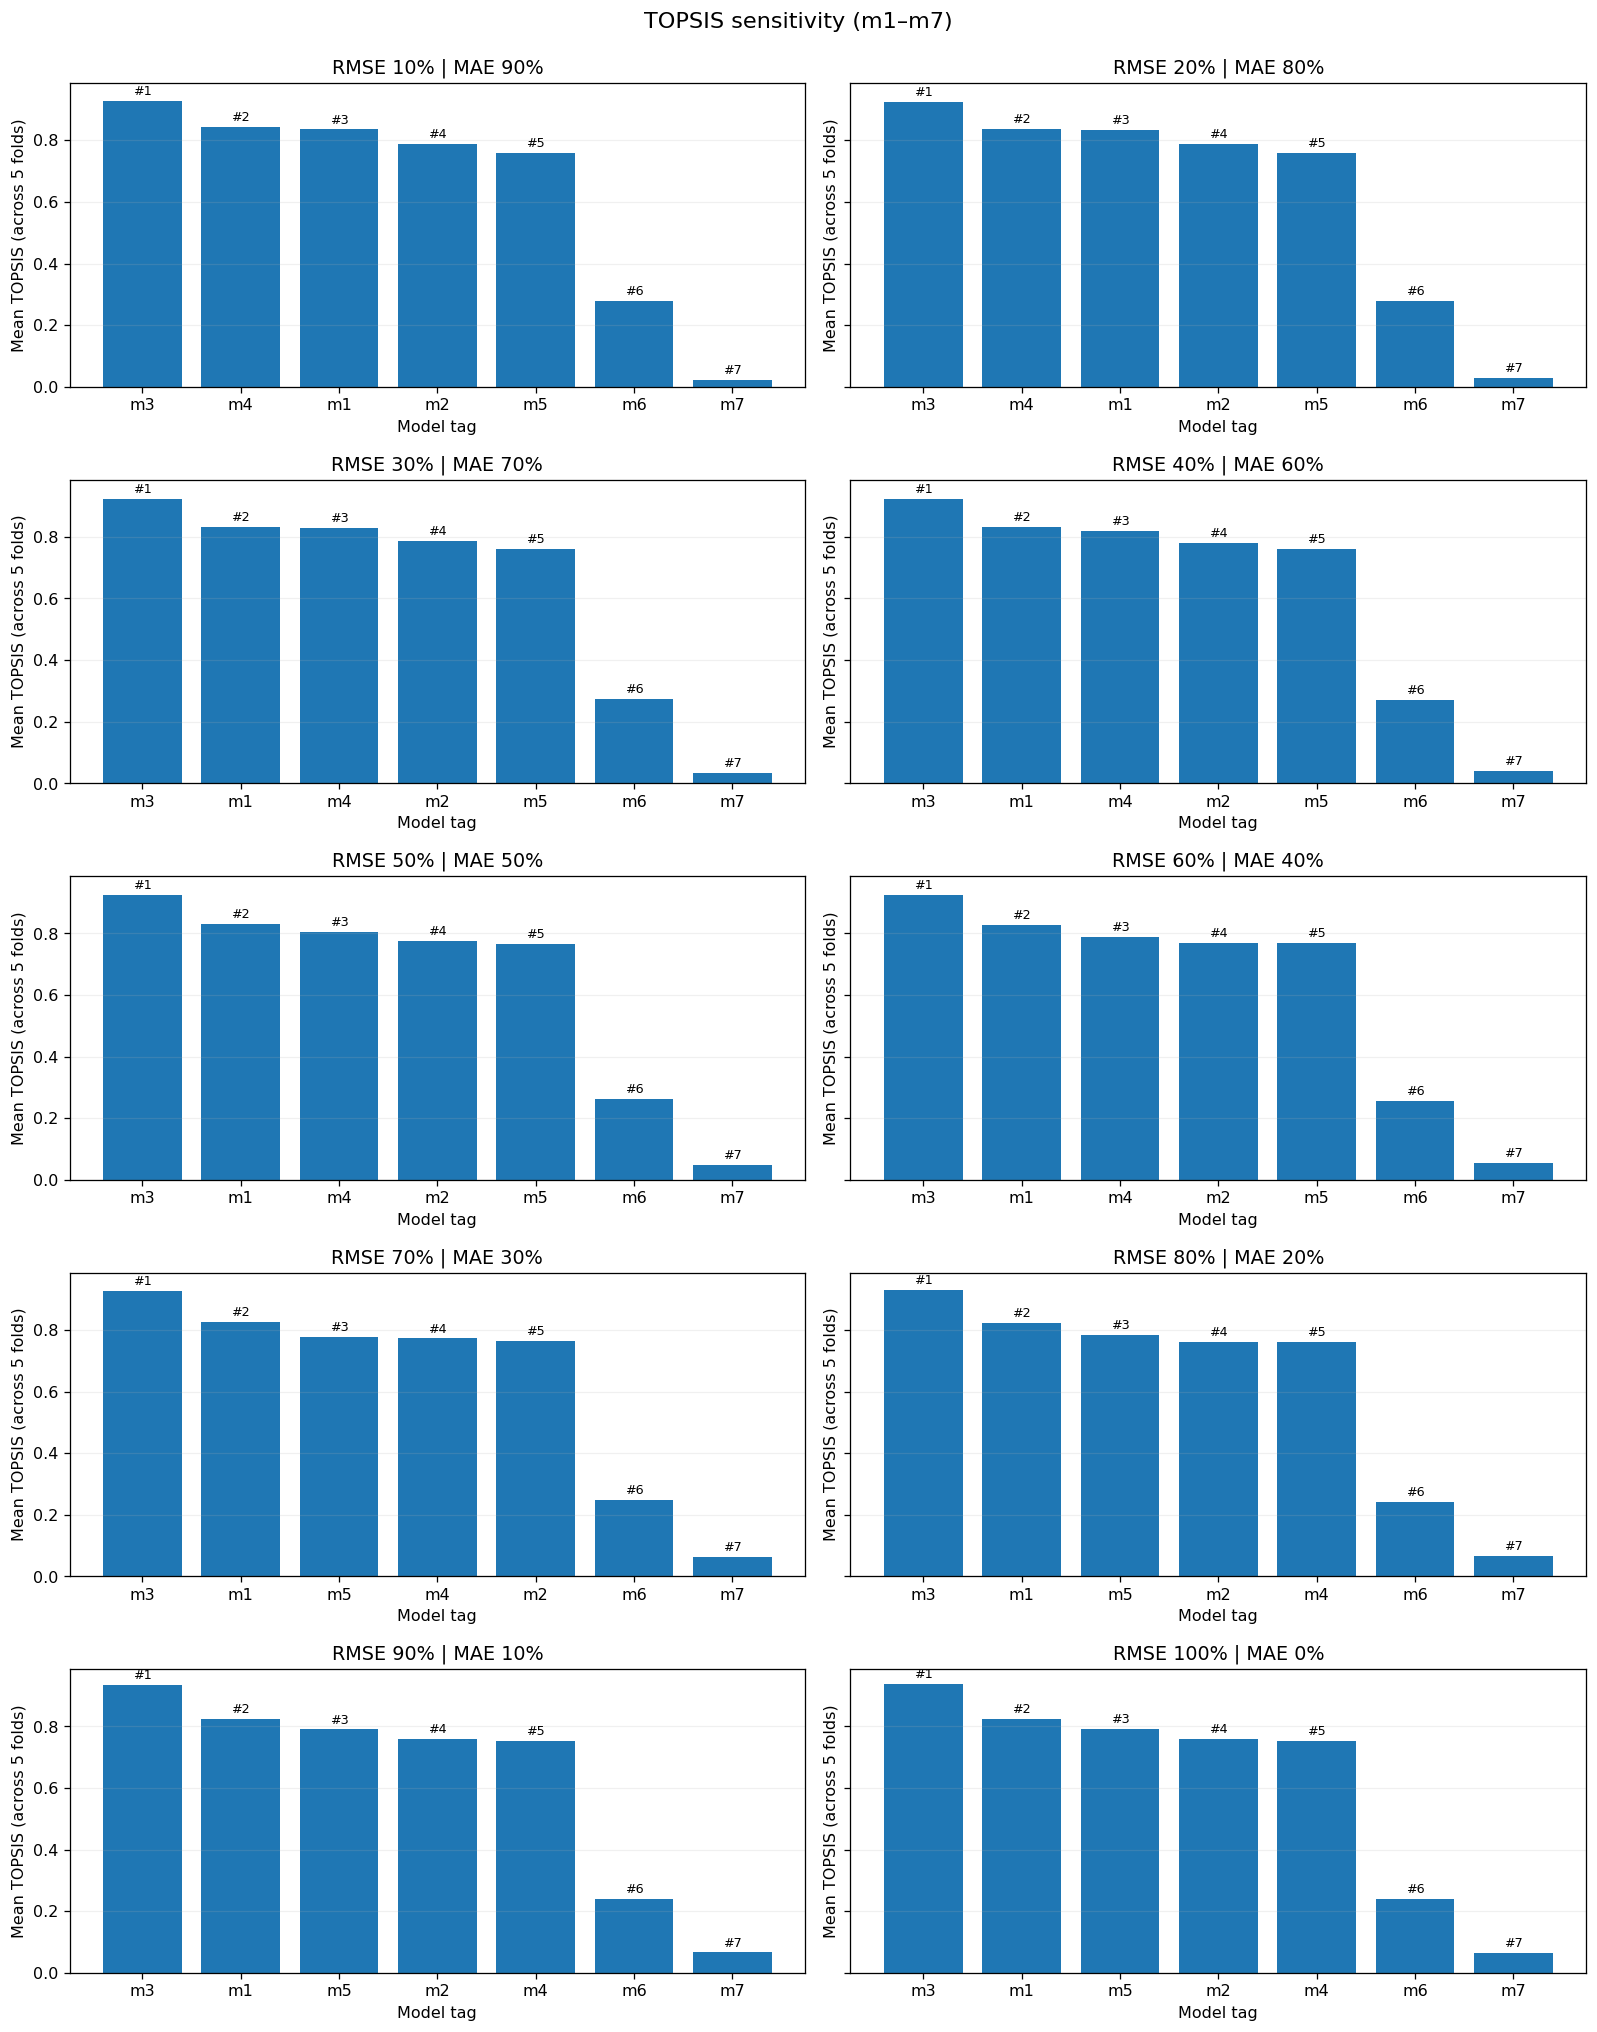

In [31]:
fig, axs = plt.subplots(5, 2, figsize=(14, 18), sharey=True)

for ax, _scenario in zip(axs.ravel(), range(1, 11)):
    _g = weight_scenarios_df[weight_scenarios_df.Weight_Scenario == _scenario].sort_values('Rank')
    ax.bar(_g['Model_Tag'], _g['Mean_TOPSIS'])
    for _x, (_score, _rank) in enumerate(zip(_g['Mean_TOPSIS'], _g['Rank'])):
        ax.text(_x, _score + 0.01, f'#{int(_rank)}', ha='center', va='bottom', fontsize=8)
    _wr = float(_g['Weight_RMSE'].iloc[0])
    _wm = float(_g['Weight_MAE'].iloc[0])
    ax.set_title(f'RMSE {int(round(_wr * 100))}% | MAE {int(round(_wm * 100))}%')
    ax.set_xlabel('Model tag')
    ax.set_ylabel('Mean TOPSIS (across 5 folds)')
    ax.grid(axis='y', alpha=0.18)


fig.suptitle('TOPSIS sensitivity (m1–m7)', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(OUT / 'Sensitivity.png', dpi=190, bbox_inches='tight')
fig.set_dpi(115)


plt.show()
plt.close(fig)

base_excel_sheets = _excel_sheets
_excel_sheets = []

In [32]:
try:
    _s1 = _addsheet('Solution1')
    _put(_s1, 1, 1, f'RMSE folds | {HORIZON_Min} min', 1)
    _line(_s1, 2, 1, ['Fold'] + REPORT_MODEL_ORDER, 2)
    for _f in range(1, 6):
        _line(_s1, 2 + _f, 1,
            [f'Fold {_f}'] + [float(adjusted_folds[(adjusted_folds.Fold == _f) & (adjusted_folds.Model == _m)].RMSE.iloc[0]) for _m in REPORT_MODEL_ORDER])
    _line(_s1, 8, 1, ['Mean ± SD'] + [_pm(adjusted_summary.loc[_m, 'RMSE_Mean'],
        adjusted_summary.loc[_m, 'RMSE_SD']) for _m in REPORT_MODEL_ORDER], 3)
    _line(_s1, 11, 1, ['Model', 'MAE Mean ± SD', 'RMSE Mean ± SD', 'R² Mean ± SD',
        'S2 Fold-mean TOPSIS', 'Rank'], 2)
    _ranked = sorted(REPORT_MODEL_ORDER, key=lambda _m: float(adjusted_summary.loc[_m,
        'S2_5FoldMean_2C_Primary']), reverse=True)
    for _r, _m in enumerate(_ranked, 12):
        _z = adjusted_summary.loc[_m]
        _line(_s1, _r, 1, [_m, _pm(_z.MAE_Mean, _z.MAE_SD), _pm(_z.RMSE_Mean, _z.RMSE_SD),
            _pm(_z.R2_Mean, _z.R2_SD, 4), float(_z.S2_5FoldMean_2C_Primary), int(_z.Primary_Rank)])
    _put(_s1, 21, 1, '21 model pairs', 1)
    _line(_s1, 22, 1,
        ['Models', 'Fold RMSE p(t)', 'Fold RMSE p(Wilcoxon)', 'Δ RMSE fold mean',
        'Δ RMSE OOF', 'Day-block 95% CI', 'p day-block', 'p TOPSIS 2C'], 2)
    for _r, (_a, _b) in enumerate(_compare_pairs, 23):
        _pt = adjusted_pair_tests.query('Model_A==@_a and Model_B==@_b and Metric=="RMSE"').iloc[0]
        _p2 = adjusted_pair_tests.query('Model_A==@_a and Model_B==@_b and Metric=="TOPSIS_2C_Equal"').iloc[0]
        _dd = day_pair_tests.query('Model_A==@_a and Model_B==@_b').iloc[0]
        _line(_s1, _r, 1, [f'{_a} vs {_b}', float(_pt.Paired_t_p), float(_pt.Wilcoxon_p),
            float(_pt.Delta_Mean), float(_dd.Delta_RMSE_AminusB),
            f'[{_dd.Bootstrap_95CI_Lower:.2f}, {_dd.Bootstrap_95CI_Upper:.2f}]',
            float(_dd.Approx_TwoSided_p_centered_block_bootstrap), float(_p2.Paired_t_p)])
    _put(_s1, 49, 1, 'Past labels only; eight features.',
        4)
    _s2 = _addsheet('S2. TOPSIS for each fold')
    for _f, _start in [(1, 1), (2, 12), (3, 23), (4, 34), (5, 45)]:
        _put(_s2, _start, 1, f'Final Fold {_f}: actual MAE, RMSE, R², TOPSIS 2C and 3C', 1)

        _line(_s2, _start + 1, 1, ['Model', 'MAE', 'RMSE', 'R²', 'TOPSIS 2C (equal weights)',
            'TOPSIS 3C (equal)'], 2)
        for _r, _m in enumerate(REPORT_MODEL_ORDER, _start + 2):
            _v = adjusted_folds.query('Model==@_m and Fold==@_f').iloc[0]
            _line(_s2, _r, 1, [_m, float(_v.MAE), float(_v.RMSE), float(_v.R2),
                float(_v.TOPSIS_2C_Equal), float(_v.TOPSIS_3C_Equal)])
    for _base, _crit, _title in [(1, 'TOPSIS_2C_Equal', 'Table R1: two criteria (equal weights)'),
        (13, 'TOPSIS_3C_Equal', 'Table R1: three criteria alternative')]:
        _put(_s2, _base, 8, _title, 1)
        _line(_s2, _base + 1, 8,
                ['Model', 'Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5',
            'Mean ± SD'], 2)
        for _r, _m in enumerate(REPORT_MODEL_ORDER, _base + 2):
            _v = adjusted_folds[adjusted_folds.Model == _m].sort_values('Fold')[_crit].to_numpy(float)
            _line(_s2,
                    _r, 8, [_m] + list(_v) + [_pm(_v.mean(), _v.std(ddof=1), 4)])
    _put(_s2, 26, 8, 'Table 2: 2C fold ranking', 1)
    _line(_s2, 27, 8, ['Model', 'MAE ± SD', 'RMSE ± SD', 'R² ± SD', 'TOPSIS fold 2C ± SD',
        'Fold-based rank'], 2)
    for _r, _m in enumerate(_ranked, 28):
        _z = adjusted_summary.loc[_m]
        _line(_s2, _r, 8, [_m, _pm(_z.MAE_Mean, _z.MAE_SD), _pm(_z.RMSE_Mean, _z.RMSE_SD),
            _pm(_z.R2_Mean, _z.R2_SD, 4), _pm(_z.Top2_Mean, _z.Top2_SD, 4), int(_z.Primary_Rank)])
    _put(_s2, 39, 8, '3C alternative', 1)
    _line(_s2, 40, 8, ['Model', 'MAE ± SD', 'RMSE ± SD', 'R² ± SD', 'TOPSIS 3C ± SD', 'Rank'], 2)

    _three_rank = sorted(REPORT_MODEL_ORDER, key=lambda _m: float(adjusted_summary.loc[_m,
        'Top3_Mean']), reverse=True)
    for _r, _m in enumerate(_three_rank, 41):
        _z= adjusted_summary.loc[_m]
        _line(_s2, _r, 8, [_m, _pm(_z.MAE_Mean, _z.MAE_SD), _pm(_z.RMSE_Mean,
                _z.RMSE_SD),
            _pm(_z.R2_Mean, _z.R2_SD, 4), _pm(_z.Top3_Mean, _z.Top3_SD, 4), _r - 40])
    _put(_s2, 57, 1,
        'Primary 2C: 50/50. Ten weights: sensitivity.',
        4)
    _put(_s2, 59, 1, 'Five folds; causal feedback only.',
        4)
    _s3 = _addsheet('Sensitivity_10Weights')
    _put(_s3, 1, 1, 'TOPSIS sensitivity', 1)
    _line(_s3, 2, 1, ['Scenario', 'Weight RMSE',
            'Weight MAE', 'Model', 'Model tag',
        'Mean TOPSIS across folds', 'SD across folds', 'Rank'], 2)
    _row = 3
    for _scenario in range(1, 11):
        _g = weight_scenarios_df[weight_scenarios_df.Weight_Scenario == _scenario].sort_values('Rank')
        for _, _v in _g.iterrows():
            _line(_s3, _row, 1, [int(_scenario), float(_v.Weight_RMSE), float(_v.Weight_MAE),
                str(_v.Model), str(_v.Model_Tag), float(_v.Mean_TOPSIS), float(_v.SD_TOPSIS),
                int(_v.Rank)])
            _row += 1
        _row += 1
    _put(_s3, 1, 10, '10-weight summary', 1)
    _line(_s3, 2, 10, ['Model', 'Model tag', 'Mean TOPSIS', 'SD TOPSIS', 'Best rank', 'Worst rank'],
        2)
    for _r, (_, _v) in enumerate(weight_summary_df.iterrows(), 3):
        _line(_s3, _r, 10, [str(_v.Model), str(_v.Model_Tag), float(_v.Mean_TOPSIS_10Weights),
            float(_v.SD_TOPSIS_10Weights), int(_v.Best_Rank), int(_v.Worst_Rank)])
    _put(_s3, 1, 18, 'Model IDs', 1)
    _line(_s3, 2, 18, ['ID', 'Model'], 2)
    for _row, _model in enumerate(REPORT_MODEL_ORDER, 3):
        _line(_s3, _row, 18, [ModelTag_MAP[_model], _model])
    _put(_s3, 15, 10, 'Model tags', 1)
    _line(_s3, 16, 10, ['Model tag', 'Model'], 2)
    for _idx, _m in enumerate(REPORT_MODEL_ORDER, 17):
        _line(_s3, _idx, 10, [ModelTag_MAP[_m], _m])
    _sensitivity_final= weight_summary_df.sort_values(['Mean_TOPSIS_10Weights', 'Model'],
        ascending=[False, True], kind='stable').reset_index(drop=True)
    _final_title_row = 3 + 10 * (len(REPORT_MODEL_ORDER) + 1) + 2
    _put(_s3, _final_title_row, 1, 'Sensitivity ranking', 1)
    _line(_s3, _final_title_row + 1, 1, ['Rank by mean', 'Model tag', 'Model',
        'Mean TOPSIS (10 weights)', 'SD TOPSIS (10 weights)', 'Best scenario rank',
        'Worst scenario rank'], 2)
    for _rank, (_, _result) in enumerate(_sensitivity_final.iterrows(), 1):
        _line(_s3, _final_title_row + 1 + _rank, 1, [int(_rank), str(_result.Model_Tag),
            str(_result.Model), float(_result.Mean_TOPSIS_10Weights),
            float(_result.SD_TOPSIS_10Weights), int(_result.Best_Rank), int(_result.Worst_Rank)],
            3 if _rank == 1 else 0)
    _put(_s3, _final_title_row + len(_sensitivity_final) + 3, 1,
        '10-weight mean ± SD; selection uses 50/50.',
        4)
    _s4 = _addsheet('All 21 Pairwise p-values')
    _put(_s4, 1, 1, '21 paired tests', 1)
    _line(_s4, 2, 1, ['Model A', 'Model B', 'Fold paired t p', 'Fold Wilcoxon p', 'OOF RMSE(A-B)',
        '95% low', '95% high', 'Day-block p', 'Fold TOPSIS 2C p'], 2)
    for _r, (_a, _b) in enumerate(_compare_pairs, 3):
        _f=adjusted_pair_tests.query('Model_A==@_a and Model_B==@_b and Metric=="RMSE"').iloc[0]
        _t = adjusted_pair_tests.query('Model_A==@_a and Model_B==@_b and Metric=="TOPSIS_2C_Equal"').iloc[0]

        _d = day_pair_tests.query('Model_A==@_a and Model_B==@_b').iloc[0]
        _line(_s4, _r, 1, [_a, _b, float(_f.Paired_t_p), float(_f.Wilcoxon_p),
            float(_d.Delta_RMSE_AminusB), float(_d.Bootstrap_95CI_Lower),
            float(_d.Bootstrap_95CI_Upper), float(_d.Approx_TwoSided_p_centered_block_bootstrap),
            float(_t.Paired_t_p)])
    _put(_s4, 27, 1, 'Exploratory; folds overlap.', 4)
    _Final_XLSX = OUT / 'TOPSIS.xlsx'
    _write_book(_Final_XLSX)
finally:
    _excel_sheets = base_excel_sheets

## Intervals

In [33]:
from collections import deque

def conservative_quantile(arr, cover=0.8):
    vals = np.sort(np.asarray(arr, dtype=float))
    vals = vals[np.isfinite(vals)]
    return float(vals[min(len(vals) - 1, max(0, int(np.ceil((len(vals) + 1) * cover)) - 1))])

q_base = conservative_quantile(np.abs(oof_df.query('Model==@selected_model').Actual.to_numpy() - oof_df.query('Model==@selected_model').Predicted.to_numpy()))
q_final = conservative_quantile(np.abs(selected_final_oof.Actual.to_numpy() - selected_final_oof.Forecast_Final.to_numpy()))
base_train = np.asarray(train_predictions[selected_model], dtype=float)
base_test = np.asarray(test_predictions[selected_model], dtype=float)

def _feedback_frame(issues, targets, observed, forecast):
    return pd.DataFrame({'Issue_Local': pd.Series(issues).astype(str).to_numpy(),
        'Target_Local': pd.Series(targets).astype(str).to_numpy(), 'Actual': np.asarray(observed,
        dtype=float), 'Predicted': np.asarray(forecast, dtype=float)})

train_issues = issue_time[is_train].astype(str).to_numpy()

train_targets = np.asarray(target_time[is_train].astype(str))
test_issues = issue_time[is_test].astype(str).to_numpy()
test_targets = np.asarray(target_time[is_test].astype(str))
train_final_obj = causal_final_feedback(_feedback_frame(train_issues,
        train_targets, ytr, base_train), 'Issue_Local', 'Target_Local', 'Actual', 'Predicted')

final_train = train_final_obj.Forecast_Final.to_numpy(float)
final_test = selected_final_test.Forecast_Final.to_numpy(float)
train_days = np.array([d.date() for d in issue_time[is_train]])
unique_days = np.unique(train_days)
day_positions = [np.flatnonzero(train_days == d) for d in unique_days]
rng_ci = np.random.default_rng(SEED + 67)
CI_Cache = cache_dir / 'PI_Refits.pkl'
if CI_Cache.exists():
    with open(CI_Cache, 'rb') as f:
        _ci_state = pickle.load(f)
    if _ci_state.get('cache_key') != cache_key or _ci_state.get('model') != selected_model:
        raise RuntimeError('Interval checkpoint signature mismatch')
    ci_boot_base_train = _ci_state['base_train']
    ci_boot_base_test= _ci_state['base_test']
    ci_boot_final_train = _ci_state['final_train']
    ci_boot_final_test = _ci_state['final_test']
else:
    ci_boot_base_train = []
    ci_boot_base_test = []
    ci_boot_final_train = []
    ci_boot_final_test = []

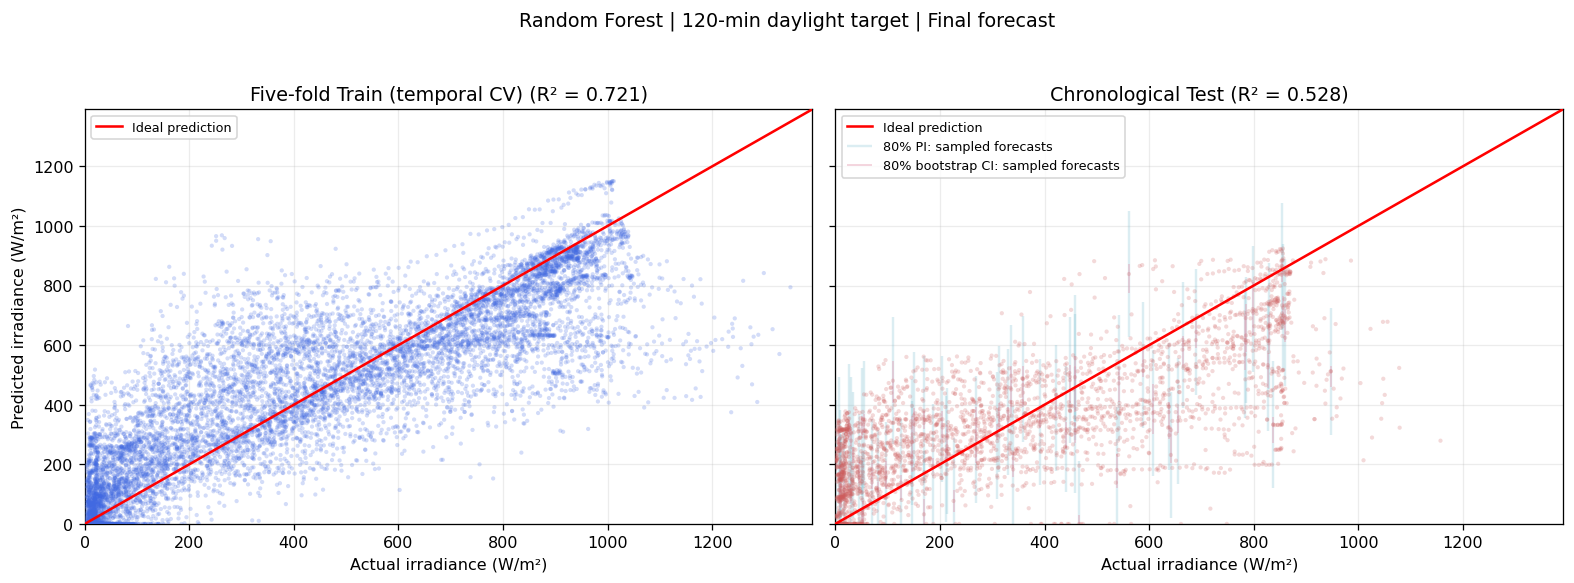

In [34]:

import shutil


for k in range(CI_BOOTSTRAP_REFITS):
    sampled_days = rng_ci.integers(0, len(day_positions), len(day_positions))
    sample_idx = np.concatenate([day_positions[ii] for ii in sampled_days])
    if k < len(ci_boot_base_test):
        continue
    _bt, _artifact = fit_model_and_predict(selected_model,
            best_parameters[selected_model], xtr[sample_idx], ytr[sample_idx], xts, return_artifact=True)
    _br = predict_fitted_model(selected_model, _artifact, xtr)
    ci_boot_base_train.append(np.asarray(_br, dtype=float))
    ci_boot_base_test.append(np.asarray(_bt, dtype=float))
    _htrain = causal_final_feedback(_feedback_frame(train_issues, train_targets, ytr, _br),
        'Issue_Local', 'Target_Local', 'Actual', 'Predicted')
    _htest = causal_final_feedback(_feedback_frame(test_issues, test_targets, yts, _bt),
        'Issue_Local', 'Target_Local', 'Actual', 'Predicted')
    ci_boot_final_train.append(_htrain.Forecast_Final.to_numpy(float))

    ci_boot_final_test.append(_htest.Forecast_Final.to_numpy(float))
    if (k + 1) % 10 == 0 or k + 1 == CI_BOOTSTRAP_REFITS:
        _atomic_pickle({'cache_key': cache_key, 'model': selected_model,
            'base_train': ci_boot_base_train, 'base_test': ci_boot_base_test,
            'final_train': ci_boot_final_train, 'final_test': ci_boot_final_test}, CI_Cache)

def _ci_limits(samples):
    vv= np.asarray(samples, dtype=float)
    low = np.maximum(0, np.quantile(vv, 0.1, axis=0))
    high= np.maximum(low, np.quantile(vv, 0.9, axis=0))
    return (low, high)

_BANDS = []
for mode, ytrain_hat, ytest_hat, boot_tr, boot_ts, radius in [('BASE', base_train, base_test,
    ci_boot_base_train, ci_boot_base_test, q_base), ('Final', final_train, final_test,
    ci_boot_final_train, ci_boot_final_test, q_final)]:
    for split, actual, pred, boot, issues, targets in [('Train_Fitted', ytr,
        ytrain_hat, boot_tr,
        train_issues, train_targets), ('Test', yts, ytest_hat, boot_ts, test_issues, test_targets)]:
        low, high = _ci_limits(boot)
        pil = np.maximum(0, pred - radius)
        pih = pred + radius
        this = pd.DataFrame({'Method': mode, 'Split': split, 'Issue_Local': issues,
            'Target_Local': targets, 'Actual': actual, 'Predicted': pred, 'CI80_Lower': low,
            'CI80_Upper': high, 'PI80_Lower': pil, 'PI80_Upper': pih})
        if mode == 'Final' and split == 'Test':
            this.to_csv(OUT / f'PI{mode}_{split}.csv', index=False)
        _BANDS.append({'Method': mode, 'Split': split, 'Nominal_PI_Coverage': 0.8,
            'Empirical_PI_Point_Coverage': float(np.mean((actual >= pil) & (actual <= pih))),
            'CI_Nominal_Level': 0.8, 'CI_is_for_conditional_mean': True,
            'Empirical_CI_point_containment_NOT_confidence_coverage': float(np.mean((actual >= low) & (actual <= high))),
            'R2': float(r2_score(actual, pred)), 'RMSE': float(np.sqrt(mean_squared_error(actual,
            pred))), 'PI_radius_train_OOF': float(radius), 'N': int(len(actual))})

interval_summary = pd.DataFrame(_BANDS)


def _draw_article_intervals(mode):
    fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.15), sharey=True)

    if mode == 'Final':
        cv = OOF_final_df[OOF_final_df.Model == selected_model]
        cv_y = cv.Actual.to_numpy(float)
        cv_pred = cv.Forecast_Final.to_numpy(float)
    else:
        cv= oof_df[oof_df.Model == selected_model]
        cv_y = cv.Actual.to_numpy(float)

        cv_pred = cv.Predicted.to_numpy(float)
    tst = pd.read_csv(OUT / f'PI{mode}_Test.csv')
    ts_y = tst.Actual.to_numpy(float)
    ts_pred = tst.Predicted.to_numpy(float)
    limit = float(max(np.quantile(np.r_[cv_y, cv_pred, ts_y, ts_pred], 0.9995) * 1.1, 100))
    for ax, yy, pp, split, color in zip(axes, [cv_y, ts_y], [cv_pred, ts_pred],
        ['Five-fold Train (temporal CV)', 'Chronological Test'], ['royalblue',
                'indianred']):
        ax.scatter(yy, pp, s=7, alpha=0.23, c=color, edgecolors='none', rasterized=True, zorder=3)
        ax.plot([0, limit], [0, limit], color='red', lw=1.6, label='Ideal prediction', zorder=5)
        ax.set(title=f'{split} (R² = {r2_score(yy, pp):.3f})', xlabel='Actual irradiance (W/m²)',
            xlim=(0, limit), ylim=(0, limit))
        ax.grid(alpha=0.23)
    ids = np.linspace(0, len(tst) - 1, num=min(65, len(tst)), dtype=int)
    draw = tst.iloc[ids].sort_values('Actual')
    axes[1].vlines(draw.Actual.to_numpy(float), draw.PI80_Lower.to_numpy(float),
        draw.PI80_Upper.to_numpy(float), color='#7abdcf', alpha=0.27, lw=1.5,
        label='80% PI: sampled forecasts')
    axes[1].vlines(draw.Actual.to_numpy(float), draw.CI80_Lower.to_numpy(float),
        draw.CI80_Upper.to_numpy(float), color='#e6a0b4', alpha=0.45, lw=1.2,
        label='80% bootstrap CI: sampled forecasts')
    axes[0].set_ylabel('Predicted irradiance (W/m²)')
    axes[0].legend(loc='upper left', fontsize=8)
    axes[1].legend(loc='upper left', fontsize=8)
    fig.suptitle(f'{selected_model} | {HORIZON_Min}-min daylight target | ' + ('Final forecast' if mode == 'Final' else 'Base forecast'),
        fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    dest = OUT / f'Forecast_{mode}.png'
    fig.savefig(dest, dpi=220, bbox_inches='tight')
    fig.set_dpi(115)
    plt.show()
    plt.close(fig)
    return dest


fig_final= _draw_article_intervals('Final')


## SHAP

/tmp/ipykernel_16/2068248580.py:51: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(raw_vals, data_used, feature_names=[Plot_FeaturesNames.get(f,


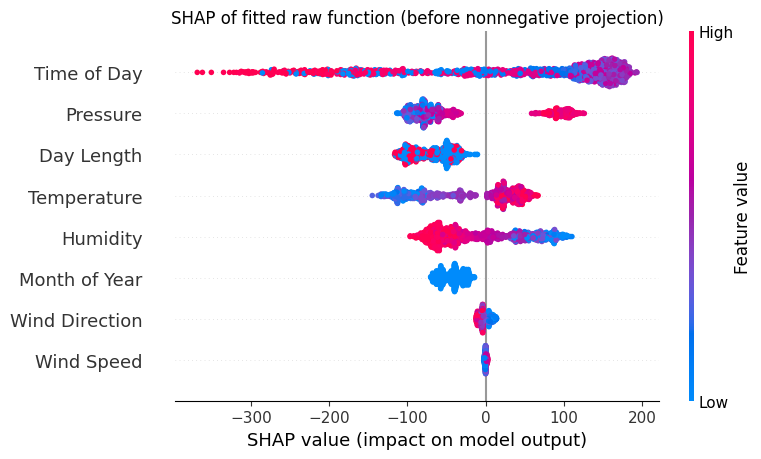

In [35]:
if RUN_SHAP:
    import shap
    if selected_model not in fitted_models:
        _, art = fit_model_and_predict(selected_model, best_parameters[selected_model], xtr, ytr,
            xts[:2], return_artifact=True)
        fitted_models[selected_model] = art
    art = fitted_models[selected_model]
    max_n = min(len(xts), SHAPTREE_SAMPLE_Size if selected_model not in ('MLP',
        'KNN') else SHAPFALLBACK_SAMPLE_Size)
    chosen_rows = np.unique(np.linspace(0, len(xts) - 1, max_n, dtype=int))
    data_used = np.asarray(xts[chosen_rows], dtype=float)
    expected_value = None
    if selected_model not in ('MLP', 'KNN'):
        try:
            explainer = shap.TreeExplainer(art)
            model_input = _lightgbm_features(data_used) if selected_model == 'LightGBM' else data_used
            raw_vals = np.asarray(explainer.shap_values(model_input))
            raw_expected = np.asarray(explainer.expected_value, dtype=float).reshape(-1)
            expected_value = float(raw_expected[0])
        except Exception as tree_error:
            chosen_rows = np.unique(np.linspace(0, len(xts) - 1, min(len(xts),
                SHAPFALLBACK_SAMPLE_Size), dtype=int))
            data_used = np.asarray(xts[chosen_rows], dtype=float)
            rng = np.random.default_rng(SEED)
            bg = xtr[rng.choice(len(xtr), size=min(SHAPBACKGROUND_Size, len(xtr)), replace = False)]
            ex = shap.Explainer(lambda a: predict_fitted_model_raw(selected_model, art, a),
                shap.maskers.Independent(bg), algorithm='permutation')
            obj = ex(data_used, max_evals=2 * len(Featues) + 1)
            raw_vals = np.asarray(obj.values)

            expected_value = float(np.asarray(obj.base_values).reshape(-1)[0])
    else:
        rng = np.random.default_rng(SEED)
        bg = xtr[rng.choice(len(xtr), size=min(SHAPBACKGROUND_Size, len(xtr)), replace=False)]
        ex = shap.Explainer(lambda a: predict_fitted_model_raw(selected_model, art, a),
            shap.maskers.Independent(bg), algorithm='permutation')
        obj = ex(data_used, max_evals=2 * len(Featues) + 1)
        raw_vals= np.asarray(obj.values)
        expected_value = float(np.asarray(obj.base_values).reshape(-1)[0])
    pred_raw = predict_fitted_model_raw(selected_model, art, data_used)
    reconstructed = expected_value + raw_vals.sum(axis=1)
    approx_residual = np.abs(reconstructed - pred_raw)
    explained_pred = physical_projection(pred_raw)
    sample_meta = pd.DataFrame({'Test_Daylight_Index': chosen_rows,
        'Issue_Row': ids[is_test][chosen_rows],
        'Issue_Time': issue_time[is_test].astype(str).to_numpy()[chosen_rows],
        'Target_Time': np.asarray(target_time[is_test].astype(str))[chosen_rows],
        'Actual_W_m2': yts[chosen_rows], 'Model_Raw_Prediction_W_m2': pred_raw,
        'Reported_Nonnegative_Prediction_W_m2': explained_pred,
        'Raw_Additivity_Residual': approx_residual})
    shap.summary_plot(raw_vals, data_used, feature_names=[Plot_FeaturesNames.get(f,
        f) for f in Featues], show=False)

    plt.title('SHAP of fitted raw function (before nonnegative projection)')
    plt.tight_layout()
    plt.savefig(OUT / 'SHAP_Beeswarm.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close()

    imp = pd.DataFrame({'Feature': Featues, 'MeanAbsSHAP': np.mean(np.abs(raw_vals),
        axis=0)}).sort_values('MeanAbsSHAP', ascending=False)
    local_index=0


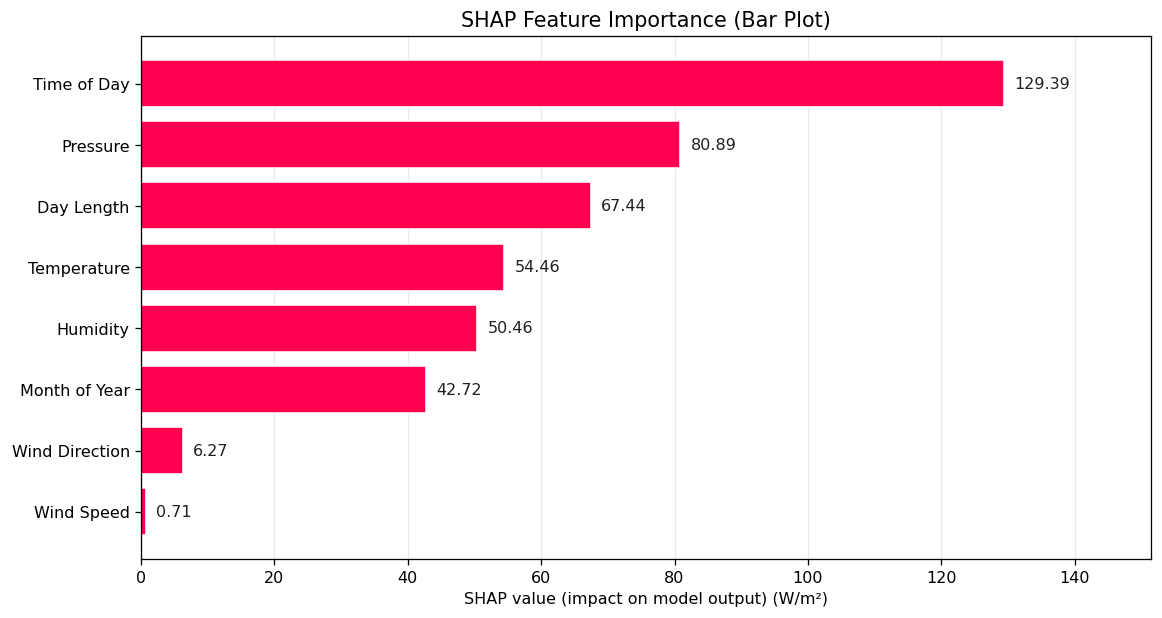

In [36]:


shv = np.asarray(raw_vals, dtype=float)
sht = np.asarray(data_used, dtype=float)


_importances = np.abs(shv).mean(axis=0)
_order = np.argsort(_importances)[::-1]
fig, ax = plt.subplots(figsize=(10.2, 5.5))

yp = np.arange(len(Featues))
importance_sorted = _importances[_order]
bars = ax.barh(yp, importance_sorted, color='#ff0051', edgecolor='white', height=0.77)
ax.set_yticks(yp, [Plot_FeaturesNames.get(Featues[k], Featues[k]) for k in _order])
ax.invert_yaxis()
ax.set_xlim(0, max(1.0, float(importance_sorted.max())) * 1.17)
for b, value in zip(bars, importance_sorted):
    ax.text(b.get_width() + max(importance_sorted) * 0.012, b.get_y() + b.get_height() / 2,
        f'{value:.2f}', ha='left', va='center', fontsize=10, color='#202020')


ax.set_xlabel('SHAP value (impact on model output) (W/m²)')
ax.set_title('SHAP Feature Importance (Bar Plot)', fontsize=13)
ax.grid(axis='x', alpha=0.28)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUT / 'SHAP_Importance.png', dpi=240, bbox_inches='tight')
fig.set_dpi(115)
plt.show()
plt.close(fig)
_temp_idx = Featues.index('Temperature')
_hour_idx = Featues.index('time_of_day')
_humidity_idx= Featues.index('Humidity')
_pressure_idx = Featues.index('Pressure')
_hours = sht[:, _hour_idx] / 60.0

from io import BytesIO as _Fig8BytesIO
from PIL import Image as _Fig8Image, ImageDraw as _Fig8Draw, ImageFont as _Fig8Font
import shap as _figure8_shap

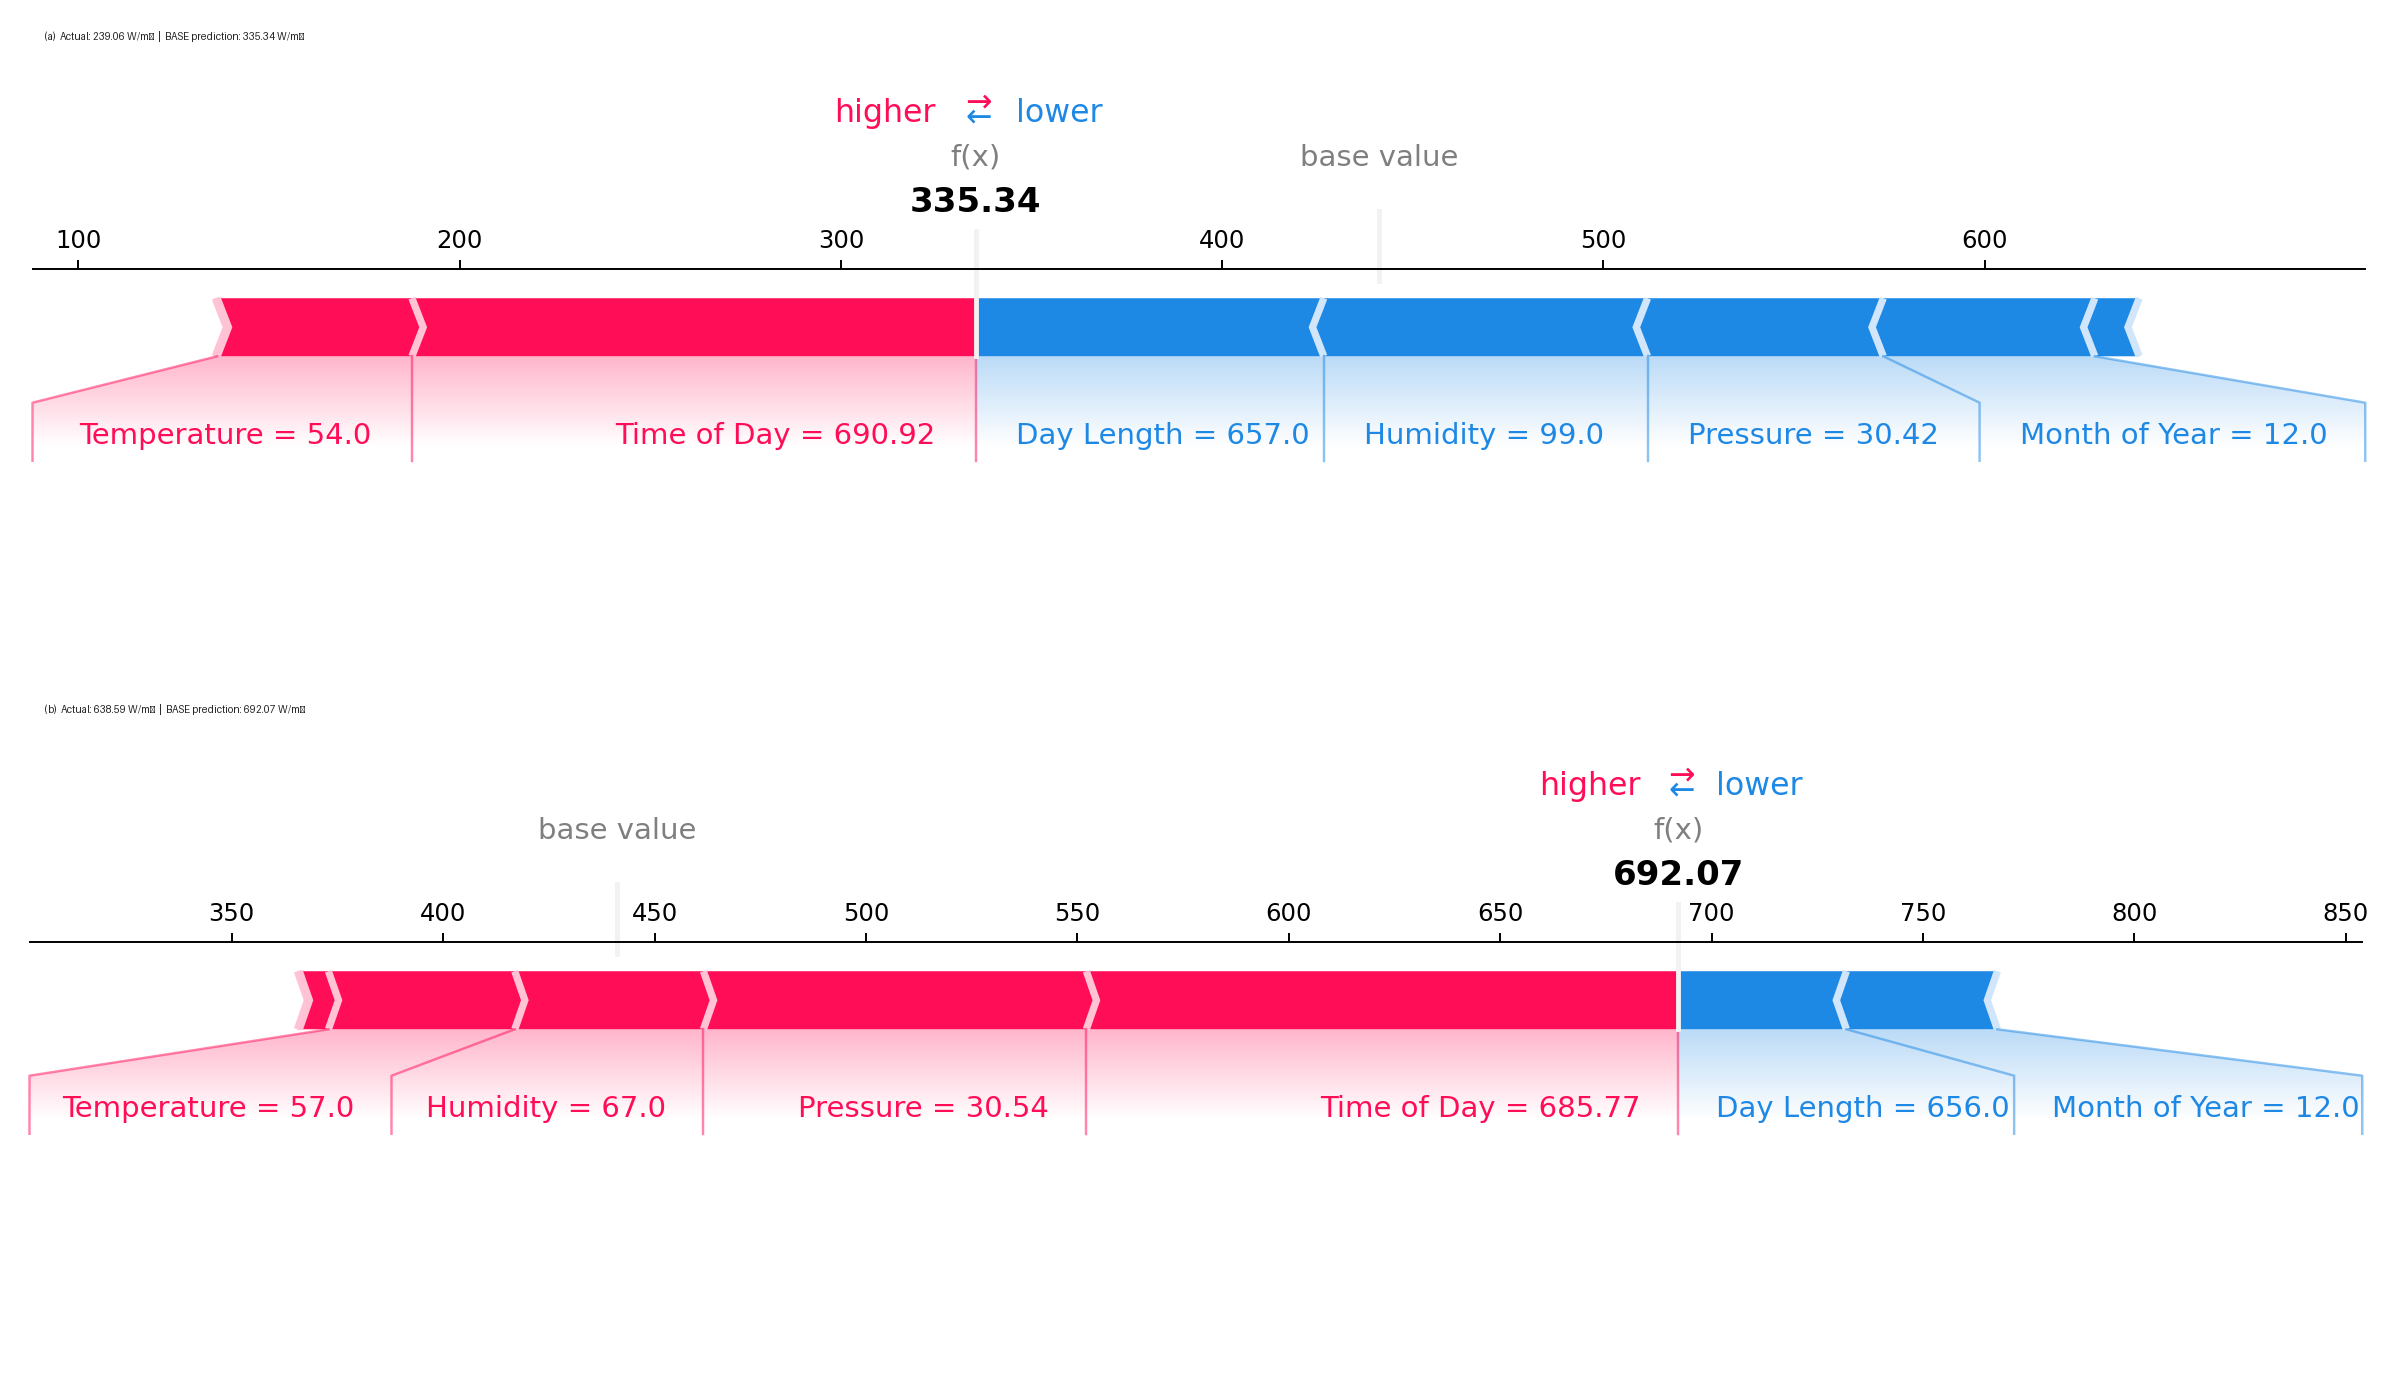

In [37]:

_figure8_cases = [{'Target_Time': '2016-12-11 13:30:36-10:00', 'Issue_Row': 26790,
    'selection': 'illustrative contrasting positive/negative SHAP contributions'},
    {'Target_Time': '2016-12-20 13:25:17-10:00', 'Issue_Row': 29372,
    'selection': 'original middle-time SHAP example retained'}]


indices = []
for _wanted in _figure8_cases:
    _hits = np.flatnonzero((sample_meta['Target_Time'].astype(str).to_numpy() == _wanted['Target_Time']) & (sample_meta['Issue_Row'].astype(int).to_numpy() == _wanted['Issue_Row']))
    indices.append(int(_hits[0]))

_local_images = []
local_out = []
_readable_names = [Plot_FeaturesNames.get(name, name) for name in Featues]
for _case_index, j in enumerate(indices):
    values = shv[j]
    _force_fig = _figure8_shap.force_plot(float(expected_value), values,
        features=np.round(np.asarray(sht[j], dtype=float), 2), feature_names=_readable_names,
        matplotlib=True, show=False, figsize=(17.2, 2.8), text_rotation=0)
    _force_fig.patch.set_facecolor('white')
    _force_buf = _Fig8BytesIO()
    _force_fig.savefig(_force_buf, format='png', dpi=175, bbox_inches='tight', facecolor='white')
    plt.close(_force_fig)
    _force_buf.seek(0)
    with _Fig8Image.open(_force_buf) as _im:
        _local_images.append(_im.convert('RGB').copy())
    local_out.append({'index_in_SHAP_sample': int(j), 'Test_Daylight_Index': int(chosen_rows[j]),
        'Expected_Base': float(expected_value), 'Raw_BASE_Prediction': float(pred_raw[j]),
        'Reconstruction': float(expected_value + shv[j].sum()),
        'Actual': float(sample_meta.iloc[j].Actual_W_m2),
        'Target_Time': str(sample_meta.iloc[j].Target_Time),
        'Issue_Row': int(sample_meta.iloc[j].Issue_Row),
        'illustration_selection': _figure8_cases[_case_index]['selection']})

_im_width = max((_im.width for _im in _local_images))
_font_path = '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf'
try:
    _font = _Fig8Font.truetype(_font_path, 24)
except OSError:
    _font = _Fig8Font.load_default()



_top_padding = 58
_gap = 78
_bottom_padding = 24
_total_height = _top_padding + sum((_im.height for _im in _local_images)) + _gap + _bottom_padding
_combined = _Fig8Image.new('RGB', (_im_width, _total_height), 'white')
_draw = _Fig8Draw.Draw(_combined)
_offset = _top_padding
for _idx, (_im, _case) in enumerate(zip(_local_images, local_out)):
    _line = ('(a)' if _idx == 0 else '(b)') + '  Actual: ' + f"{_case['Actual']:.2f}" + ' W/m²  |  '
    _line += 'BASE prediction: ' + f"{_case['Raw_BASE_Prediction']:.2f}" + ' W/m²'
    _draw.text((32, _offset - 39), _line, fill='#222222', font=_font)
    _combined.paste(_im, ((_im_width - _im.width) // 2, _offset))
    _offset += _im.height + _gap


_figure8_path = OUT / 'SHAP_Local.png'
_combined.save(_figure8_path, optimize=True)
pic = plt.figure(figsize=(_combined.width / 115, _combined.height / 115), dpi=115)
ax = pic.add_axes([0, 0, 1, 1])
ax.imshow(_combined, interpolation='nearest')
ax.axis('off')


plt.show()
plt.close(pic)

## Export

In [38]:
from pathlib import Path
import zipfile, shutil

figures = {
    'Correlation.png': 'Correlation.png', 'Bivariate_MATLAB.png': 'Bivariate.png', 'Sensitivity.png': 'Sensitivity.png', 'Forecast_Final.png': 'Forecast.png',
    'SHAP_Importance.png': 'SHAP_Importance.png', 'SHAP_Beeswarm.png': 'SHAP_Beeswarm.png', 'SHAP_Local.png': 'SHAP_Local.png'
}


books = ['CV.xlsx', 'TOPSIS.xlsx']

root = BASE / 'Paper'
if root.exists():
    shutil.rmtree(root)
(root / 'Figures').mkdir(parents=True)
(root / 'Excel').mkdir()


for src, name in figures.items():
    if src == 'Bivariate_MATLAB.png' and not (OUT / src).is_file():
        continue
    shutil.copyfile(OUT / src, root / 'Figures' / name)
for name in books:
    shutil.copyfile(OUT / name, root / 'Excel' / name)

archive = BASE / 'Solar.zip'
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    for path in sorted(root.rglob('*')):
        if path.is_file():
            z.write(path, path.relative_to(root))


keep = set(figures) | set(books)
for path in OUT.iterdir():
    if path.name not in keep:
        if path.is_dir():
            shutil.rmtree(path)
        else:
            path.unlink()

shutil.rmtree(root)
